In [1]:
import sys
print(sys.executable) # Run the program in the Xenium environment you created

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/bin/python


In [139]:
import scanpy as sc
import pandas as pd
import numpy as np
import h5py
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
import os
import squidpy as sq
import spatialdata as sd
import spatialdata_io as sio
import spatialdata_plot
from scipy import sparse
from pathlib import Path
import seaborn as sns
from adjustText import adjust_text
CONFIG_DIR = Path("Notebooks")
sys.path.append(str(CONFIG_DIR))
import importlib
import xenium_config
import cardinal_class_markers

importlib.reload(xenium_config)
importlib.reload(cardinal_class_markers)


<module 'cardinal_class_markers' from '/nfs/scistore23/sweengrp/sgobeil/Xenium Data Analysis/Xenium-MADM/Notebooks/cardinal_class_markers.py'>

In [140]:
os.chdir(
    "/nfs/scistore23/sweengrp/sgobeil/Xenium Data Analysis/Xenium-MADM"
)

In [141]:
sc.settings.verbosity = 3
# Preserve editable text in PDF and SVG
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

# Prevent global rasterization
mpl.rcParams["agg.path.chunksize"] = 10000

In [142]:
### Load the data
adata_madm = sc.read_h5ad("Processed/MADM_preprocessed.h5ad")

adata_combined = sc.read_h5ad("Processed/Xenium_allcell_reference.h5ad")

adata_neurons_SCNeuron_genes = sc.read_h5ad("Processed/Xen-MADM_neurons_SCgenes_reclustered_all_genes.h5ad")

adata_madm_query = sc.read_h5ad("Processed/MADM_mapped_neurons_all_genes.h5ad")

adata_madm_all_query = sc.read_h5ad("Processed/MADM_mapped_all.h5ad")



In [143]:
overall_dir = Path("Output_20261022")
overall_dir.mkdir(parents=True, exist_ok=True)

In [144]:
### Make marker lists

#Import the marker list CSV
markers_df = pd.read_csv("Marker_Lists_v4.csv")

# Convert each column into a list, removing empty cells, and save them in a dictionary
marker_dict = {
    cell_type: markers_df[cell_type].dropna().tolist()
    for cell_type in markers_df.columns
}

# # Filter by markers actually present in the Xenium data
# marker_dict = {
#     cell_type: [
#         gene for gene in genes
#         if gene in adata_combined.var_names
#     ]
#     for cell_type, genes in marker_dict.items()
# }

custom_SC = {
    key: marker_dict[key]
    for key in xenium_config.custom_SC_keys
}

SC_neuron = {
    key: marker_dict[key]
    for key in xenium_config.SC_neuron_keys
}

In [8]:
######################################################################################################################################################
### All cells

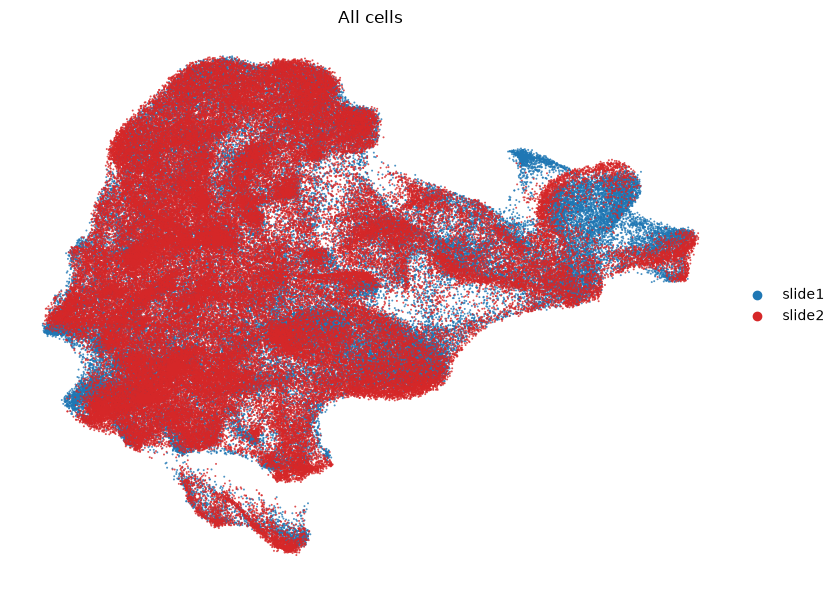

In [9]:
### UMAP with all cells colour-coded by  slide

umap_plot_dir = Path(overall_dir) / "All cells"
umap_plot_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8.5, 6))

sc.pl.umap(
    adata_combined,
    color='slide',
    layer="lognorm",
    cmap="viridis",
    frameon=False,
    ax=ax,
    show=False,
    title='All cells',
    size=8,
    alpha=0.8)

# Rasterize the UMAP points
for collection in ax.collections:
    collection.set_rasterized(True)

plt.tight_layout()

fig.savefig(
    umap_plot_dir / "all_cells_umap_slides.pdf",
    dpi=600,
    bbox_inches="tight")

plt.show()
plt.close(fig)

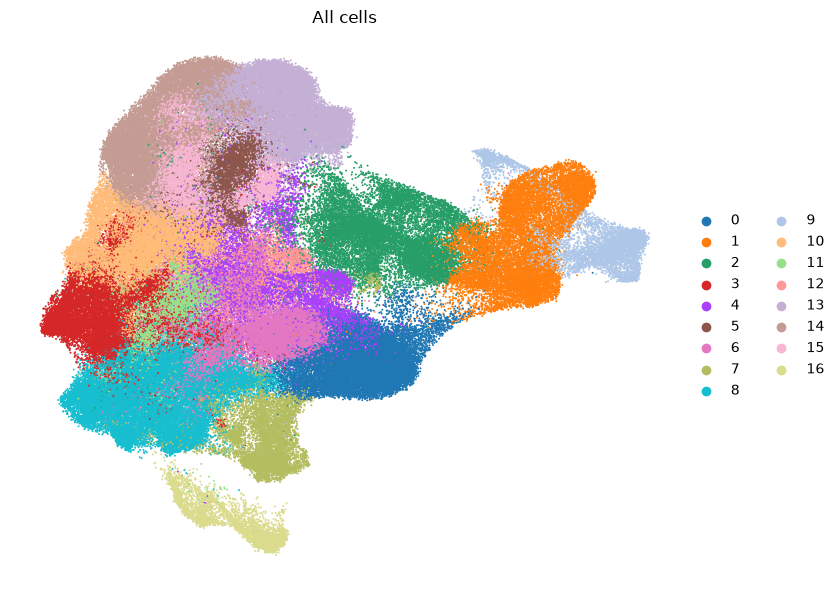

In [10]:
### UMAP with all cells colour-coded by leiden

fig, ax = plt.subplots(figsize=(8.5, 6))

sc.pl.umap(
    adata_combined,
    color='leiden',
    layer="lognorm",
    cmap="viridis",
    frameon=False,
    ax=ax,
    show=False,
    title='All cells',
    size=8)

# Rasterize the UMAP points
for collection in ax.collections:
    collection.set_rasterized(True)

plt.tight_layout()

fig.savefig(
    umap_plot_dir / "all_cells_umap_leiden.pdf",
    dpi=600,
    bbox_inches="tight")

plt.show()
plt.close(fig)

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


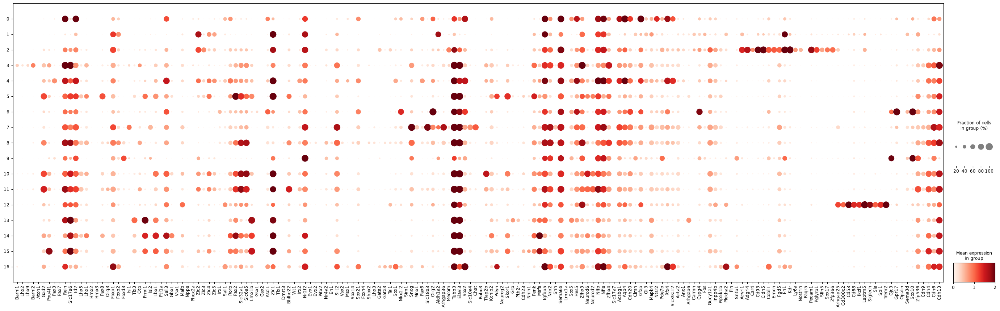

In [11]:
### Dot plot of all cells
unique_values = list(dict.fromkeys(
    value
    for values in custom_SC.values()
    for value in values
))

dp = sc.pl.dotplot(adata_combined, var_names=unique_values, groupby="leiden", layer="lognorm", standard_scale=None, figsize=(35,10), dendrogram=False, cmap="Reds", vmin=0, vmax=2, linewidth=0, return_fig=True)
dp.savefig(umap_plot_dir / "all_cells_custom_SC_genes.svg", dpi=600, bbox_inches="tight")

Neuronal markers:
['Tubb3', 'Elavl3']
computing score 'neuron_score'
    finished: added
    'neuron_score', score of gene set (adata.obs).
    10 total control genes are used. (0:00:00)


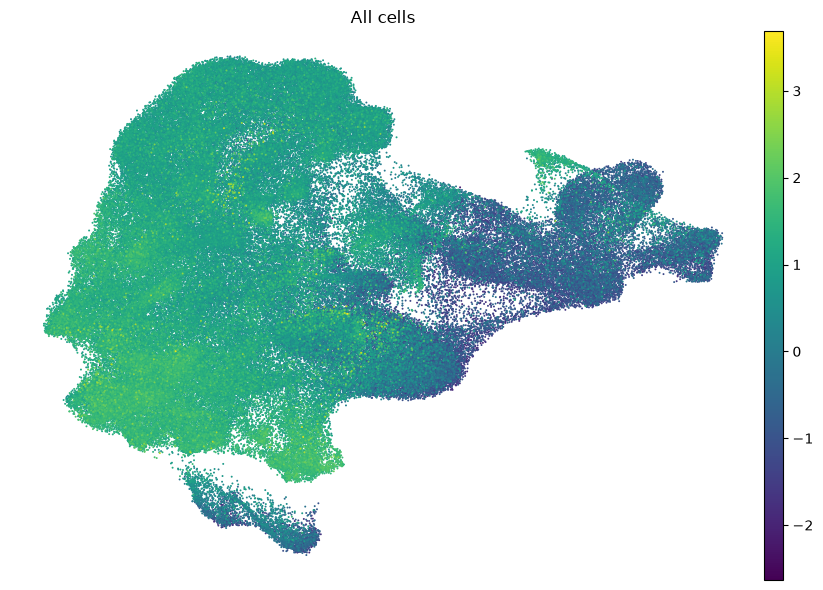

In [12]:
### UMAP with all cells colour-coded by neuron score

umap_plot_dir = Path(overall_dir) / "All cells"

# Give each cell a neuron score
# for each cell, calculates the average log-normalized expression of the neuronal genes. It then subtracts the average expression of a set of control 
# genes chosen to have similar overall expression levels to the marker genes.

neuron_markers = custom_SC["neurons"]

print("Neuronal markers:")
print(neuron_markers)

sc.tl.score_genes(
    adata_combined,
    gene_list=neuron_markers,
    score_name="neuron_score",
    layer="lognorm",
    use_raw=False
)

fig, ax = plt.subplots(figsize=(8.5, 6))

sc.pl.umap(
    adata_combined,
    color='neuron_score',
    layer="lognorm",
    cmap="viridis",
    frameon=False,
    ax=ax,
    show=False,
    title='All cells',
    size=8)

# Rasterize the UMAP points
for collection in ax.collections:
    collection.set_rasterized(True)

plt.tight_layout()

fig.savefig(
    umap_plot_dir / "all_cells_umap_neuron score.pdf",
    dpi=600,
    bbox_inches="tight")

plt.show()
plt.close(fig)



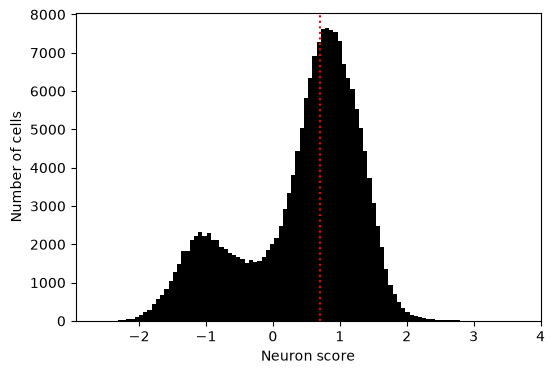

In [13]:
### Neuron score histogram
fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(
    adata_combined.obs["neuron_score"],
    bins=100,
    color = 'k'
)

# Red dotted vertical line at 0.7
ax.axvline(
    x=0.7,
    color="red",
    linestyle=":",
    linewidth=1.5
)

plt.xlabel("Neuron score")
plt.ylabel("Number of cells")

fig.savefig(
    umap_plot_dir / "neuron_score_hist.pdf",
    dpi=600,
    bbox_inches="tight")

plt.show()
plt.close(fig)

In [14]:
######################################################################################################################################################
### Neurons

Index(['x', 'y', 'z', 'feature_name', 'cell_id', 'codeword_index', 'qv',
       'codeword_category', 'fov_name', 'transcript_id', 'is_gene',
       'overlaps_nucleus', 'nucleus_distance'],
      dtype='object')


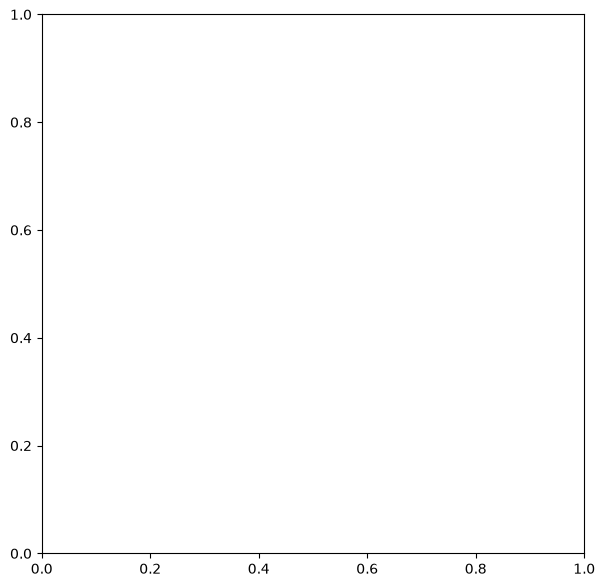

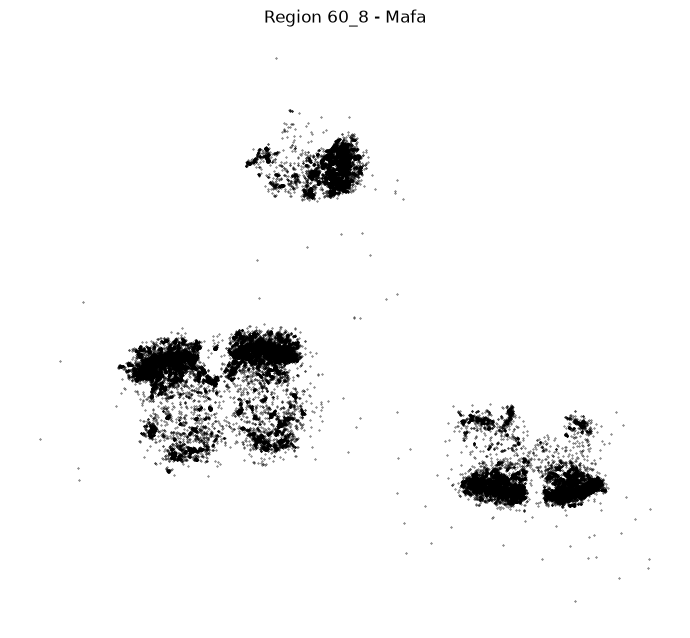

In [15]:
### Spatial transcript plots

region = "Region 60_8"

genes_to_plot = ["Mafa"]

gene_colors = {
    "Nppa": 'k',
    "Mafa": 'k',
    "Sall3": 'k',
    "Isl1": 'k',
    "Isl2": 'k',
    "Barhl1": 'k',
    "Foxd3": 'k',
    "Dmrt3":'k',
    "Evx1": 'k', 
    "En1": 'k',
    "Vsx2": 'k',
    "Nkx2-2": 'k',
    "Foxp1": 'k',
    "Lhx3": 'k',
    "Tubb3": 'k',
    
}

# Load the original SpatialData object for this region
data = sd.read_zarr(
    "data_60_Region8.zarr"
)

# Get individual transcript points
transcripts = data["transcripts"].compute()

print(transcripts.columns)

# Keep desired genes
transcripts_plot = transcripts[
    transcripts["feature_name"].isin(genes_to_plot)
].copy()

fig, ax = plt.subplots(figsize=(7, 7))

plot_dir = Path(overall_dir) / "Spatial_transcripts"
plot_dir.mkdir(parents=True, exist_ok=True)

for gene in genes_to_plot:

    sub = transcripts_plot[
        transcripts_plot["feature_name"] == gene
    ]

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.scatter(
        sub["x"],
        sub["y"],
        s=0.1,
        color=gene_colors[gene]
    )

    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
    ax.set_title(f"{region} - {gene}")

    plt.tight_layout()

    fig.savefig(
        plot_dir / f"{region.replace(' ', '_')}_{gene}.svg",
        bbox_inches="tight"
    )

    plt.show()

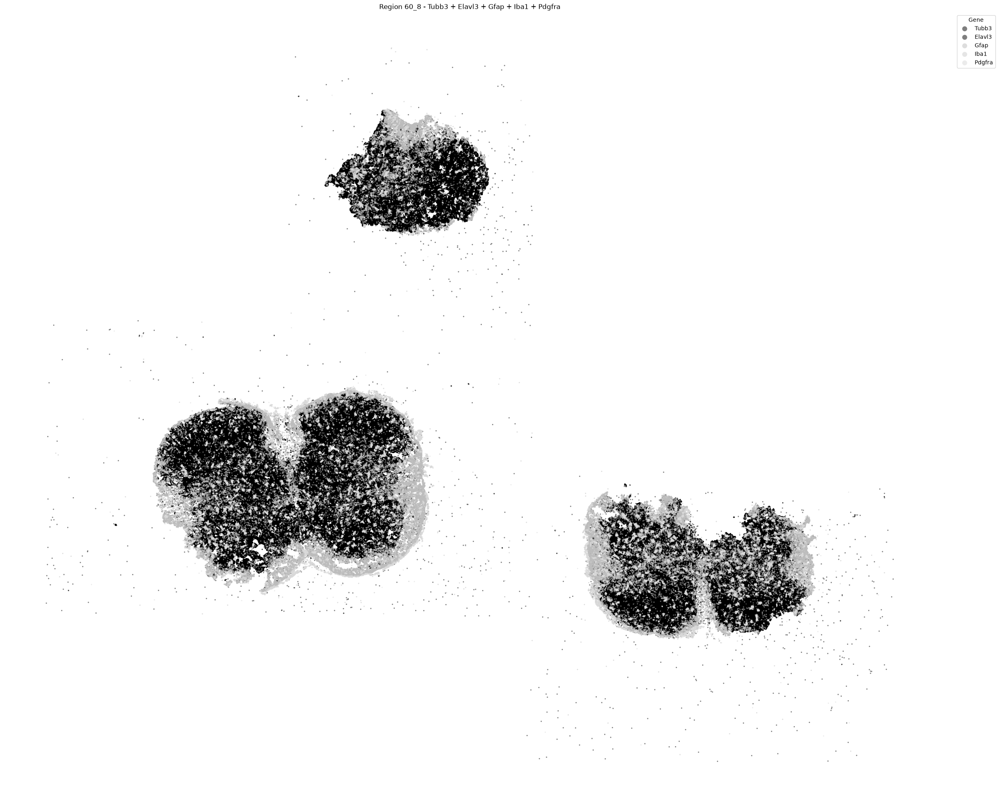

In [16]:
### Neurons vs glia
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Tubb3", "Elavl3", "Gfap", "Iba1", "Pdgfra" ]

overlay_colors = {
    "Tubb3": "k",
    "Elavl3": "k",
    "Gfap": "#BDBDBD",
    "Iba1": "#CCCCCC",
    "Pdgfra": "#D9D9D9",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=5,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

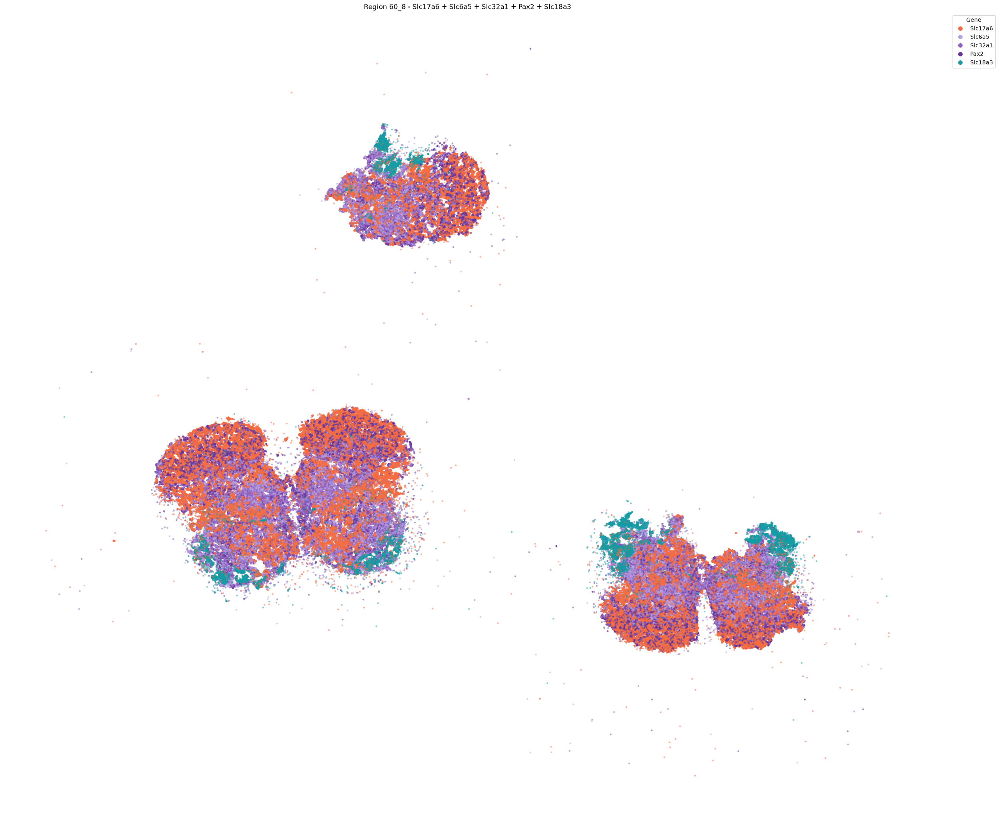

In [17]:
## NTs
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Slc17a6", "Slc6a5", "Slc32a1", "Pax2", "Slc18a3"]

overlay_colors = {
    "Slc17a6": "#F46D43",
    "Slc6a5": "#B9A3E3",
    "Slc32a1": "#9061C2",
    "Pax2": "#663399",
    "Slc18a3": "#159CA4",
}

# Keep only transcripts from genes to overlay
overlay_df = transcripts[
    transcripts["feature_name"].isin(genes_to_overlay)
].copy()

# Randomize individual transcript plotting order
overlay_df = overlay_df.sample(
    frac=1,
    random_state=0
)

fig, ax = plt.subplots(figsize=(25, 25))

ax.scatter(
    overlay_df["x"],
    overlay_df["y"],
    s=10,
    c=overlay_df["feature_name"].map(overlay_colors),
    alpha=0.5,
    edgecolors="none",
    rasterized=True
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=overlay_colors[gene],
        markeredgecolor="none",
        markersize=8,
        label=gene
    )
    for gene in genes_to_overlay
]

ax.legend(
    handles=legend_handles,
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

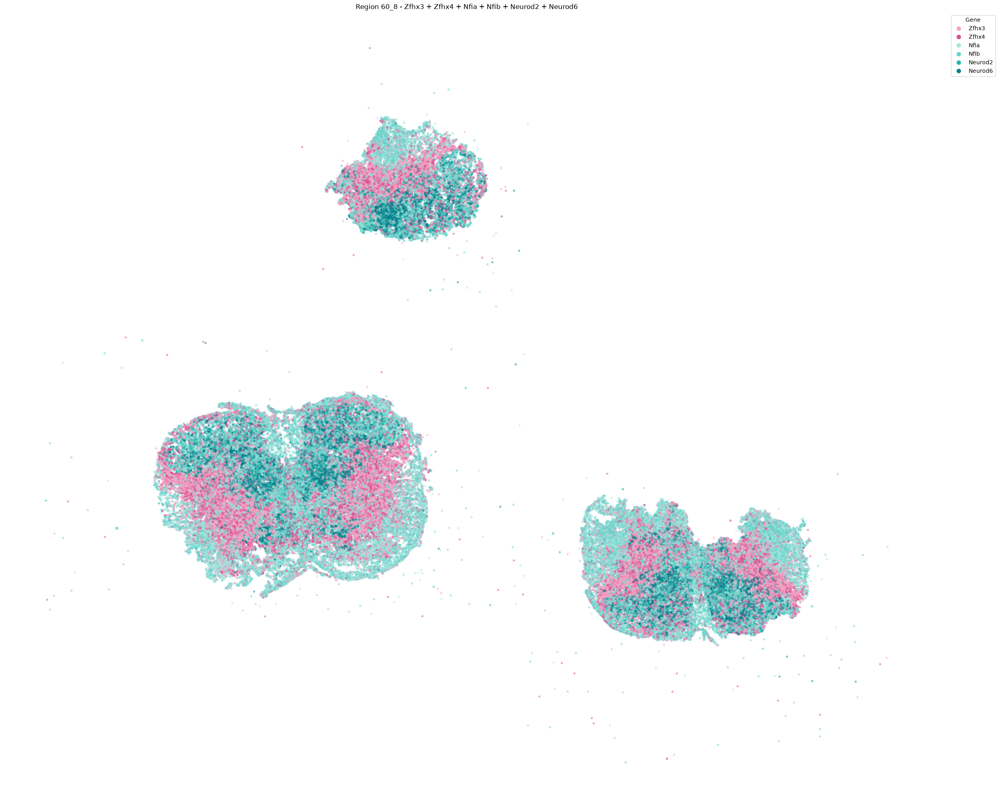

In [18]:
## TTFs
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Zfhx3", "Zfhx4", "Nfia", "Nfib", "Neurod2", "Neurod6"]

overlay_colors = {
    "Zfhx3":    "#F4A3C4",
    "Zfhx4":    "#D94F91",
    "Nfia":     "#A3E8DF",
    "Nfib":     "#65D3CB",
    "Neurod2":  "#29B6AD",
    "Neurod6":  "#087F8C",
}

# Keep only transcripts from genes to overlay
overlay_df = transcripts[
    transcripts["feature_name"].isin(genes_to_overlay)
].copy()

# Randomize individual transcript plotting order
overlay_df = overlay_df.sample(
    frac=1,
    random_state=0
)

fig, ax = plt.subplots(figsize=(25, 25))

ax.scatter(
    overlay_df["x"],
    overlay_df["y"],
    s=15,
    c=overlay_df["feature_name"].map(overlay_colors),
    alpha=0.5,
    edgecolors="none",
    rasterized=True
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=overlay_colors[gene],
        markeredgecolor="none",
        markersize=8,
        label=gene
    )
    for gene in genes_to_overlay
]

ax.legend(
    handles=legend_handles,
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()


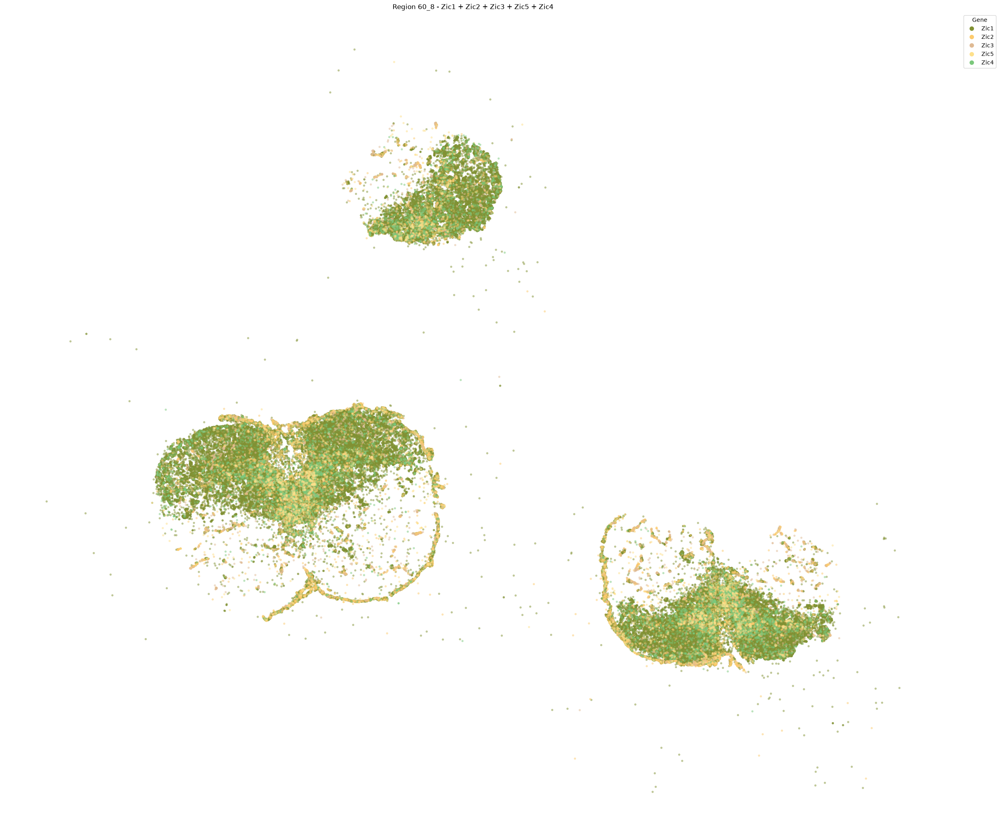

In [19]:
## Zics
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Zic1", "Zic2", "Zic3", "Zic5", "Zic4",]

overlay_colors = {
    "Zic1":    "#819133",
    "Zic4":    "#7BC87C",
    "Zic3":     "#DFBA94",
    "Zic2":     "#FDCB6E",
    "Zic5":  "#FEE08B",
}

# Keep only transcripts from genes to overlay
overlay_df = transcripts[
    transcripts["feature_name"].isin(genes_to_overlay)
].copy()



fig, ax = plt.subplots(figsize=(25, 25))

ax.scatter(
    overlay_df["x"],
    overlay_df["y"],
    s=15,
    c=overlay_df["feature_name"].map(overlay_colors),
    alpha=0.5,
    edgecolors="none",
    rasterized=True
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=overlay_colors[gene],
        markeredgecolor="none",
        markersize=8,
        label=gene
    )
    for gene in genes_to_overlay
]

ax.legend(
    handles=legend_handles,
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()


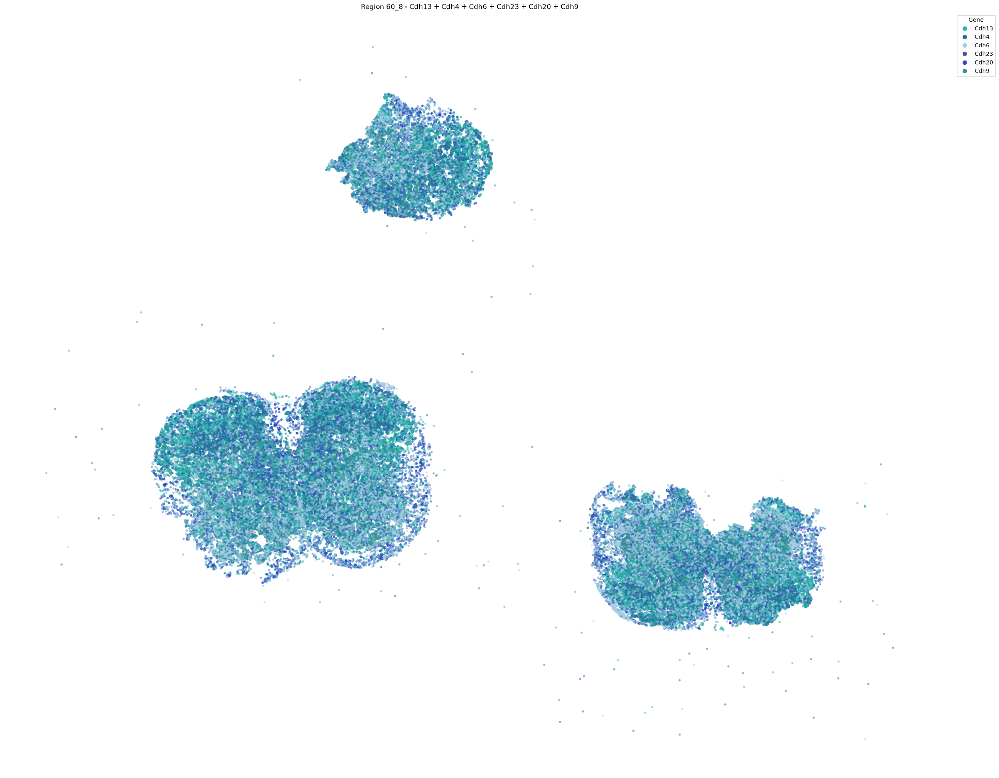

In [20]:
## Cadherins
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Cdh13", "Cdh4", "Cdh6",  "Cdh23", "Cdh20", "Cdh9"]

overlay_colors = {
    "Cdh4":    "#286F9E",
    "Cdh6":    "#A6CEE3",
    "Cdh9":     "#369194",
    "Cdh13":     "#29B6AD",
    "Cdh23":  "#574F9C",
    "Cdh20":  "#3544C9",
}

# Keep only transcripts from genes to overlay
overlay_df = transcripts[
    transcripts["feature_name"].isin(genes_to_overlay)
].copy()

fig, ax = plt.subplots(figsize=(25, 25))

ax.scatter(
    overlay_df["x"],
    overlay_df["y"],
    s=15,
    c=overlay_df["feature_name"].map(overlay_colors),
    alpha=0.5,
    edgecolors="none",
    rasterized=True
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=overlay_colors[gene],
        markeredgecolor="none",
        markersize=8,
        label=gene
    )
    for gene in genes_to_overlay
]

ax.legend(
    handles=legend_handles,
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()


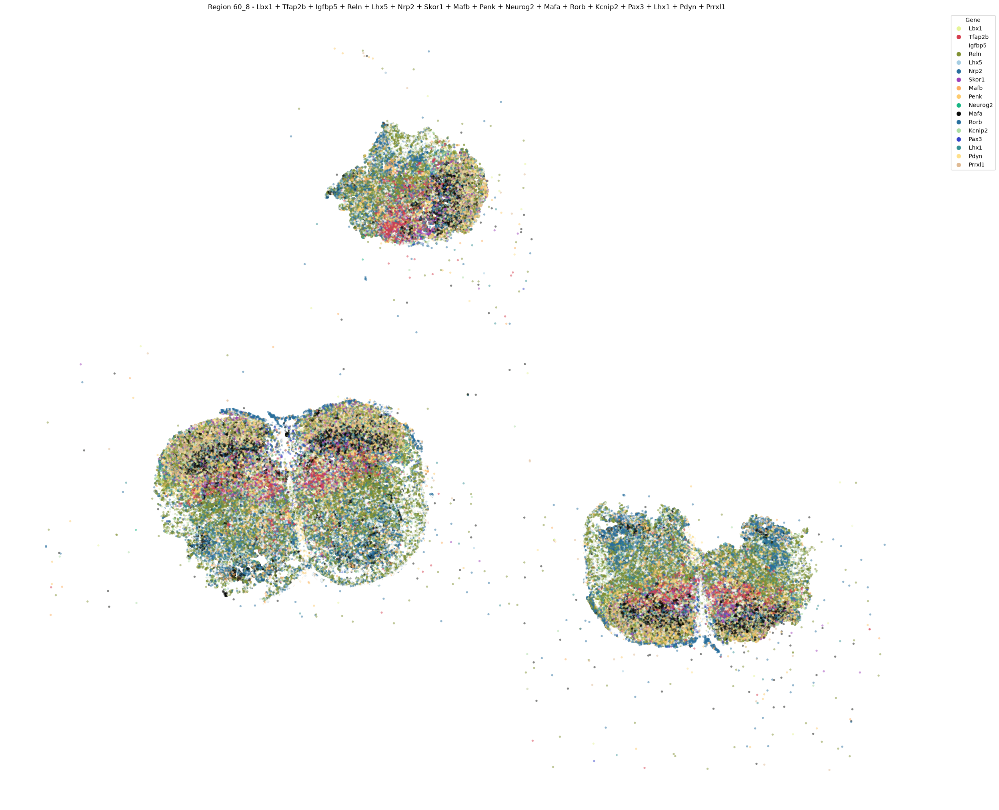

In [21]:
## dI4 subtype markers spatial plot
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Lbx1",
    "Tfap2b",
    "Igfbp5",
    "Reln",
    "Lhx5",
    "Nrp2",
    "Skor1",
    "Mafb",
    "Penk",
    "Neurog2",
    "Mafa",
    "Rorb",
    "Kcnip2",
    "Pax3",
    "Lhx1",
    "Pdyn",
    "Prrxl1"]

overlay_colors = {
    "Lbx1": "#E6F598",
    "Tfap2b": "#D53E4F",
    "Igfbp5": "#FFFFFF",
    "Reln": "#819133",
    "Lhx5": "#A6CEE3",
    "Nrp2": "#286F9E",
    "Skor1": "#9D40B9",
    "Mafb": "#FDAE61",
    "Penk": "#FDCB6E",
    "Neurog2": "#17B684",
    "Mafa": "#080A08",
    "Rorb": "#286F9E",
    "Kcnip2": "#ABDDA4",
    "Pax3": "#3544C9",
    "Lhx1": "#369194",
    "Pdyn": "#FEE08B",
    "Prrxl1": "#DFBA94",
}

# Keep only transcripts from genes to overlay
overlay_df = transcripts[
    transcripts["feature_name"].isin(genes_to_overlay)
].copy()

# Randomize individual transcript plotting order
overlay_df = overlay_df.sample(
    frac=1,
    random_state=0
)

fig, ax = plt.subplots(figsize=(25, 25))

ax.scatter(
    overlay_df["x"],
    overlay_df["y"],
    s=15,
    c=overlay_df["feature_name"].map(overlay_colors),
    alpha=0.5,
    edgecolors="none",
    rasterized=True
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=overlay_colors[gene],
        markeredgecolor="none",
        markersize=8,
        label=gene
    )
    for gene in genes_to_overlay
]

ax.legend(
    handles=legend_handles,
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()



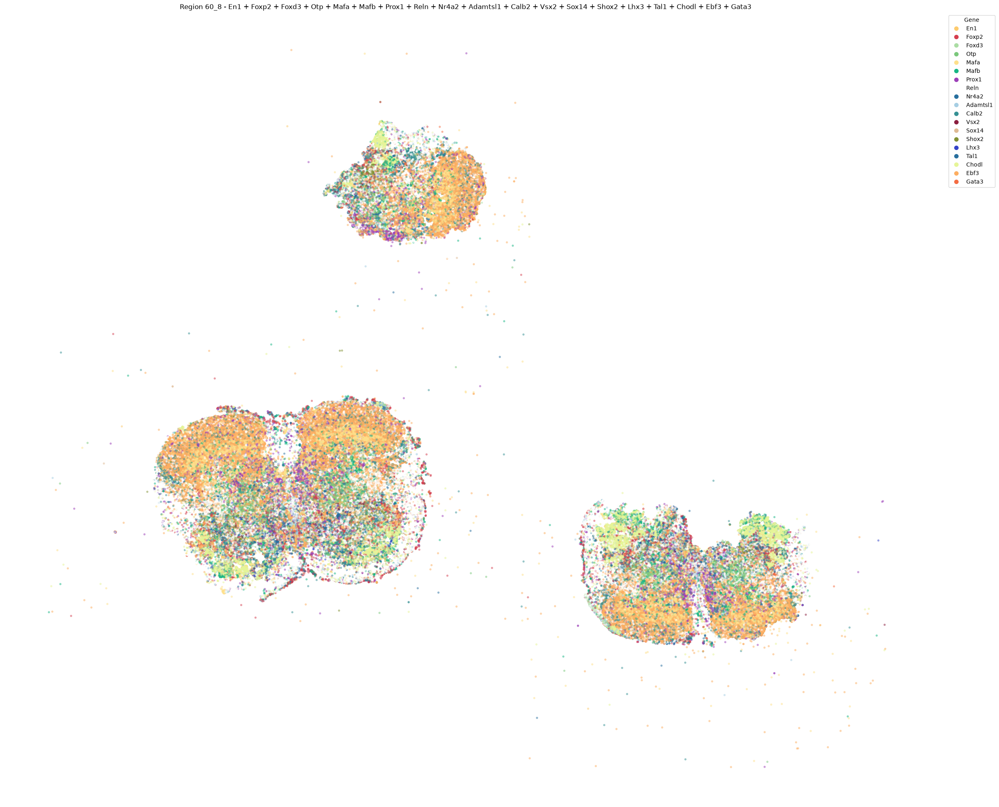

In [22]:
## V2a/V2b/V1 subtype markers spatial plot
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ['En1',
        'Foxp2',
        'Foxd3',
        'Otp',
        'Mafa',
        'Mafb',
        'Prox1',
        'Reln',
        'Nr4a2',
        'Adamtsl1',
        'Calb2',
        'Vsx2',
        'Sox14',
        'Shox2',
        'Lhx3',
        'Tal1',
        'Chodl',
        'Ebf3',
        'Gata3',]

overlay_colors = {
    "Foxp2":    "#D53E4F",
    "Foxd3":    "#ABDDA4",
    "Mafa":     "#FEE08B",
    "Mafb":     "#17B684",
    "Prox1":    "#9D40B9",
    "En1":      "#FDCB6E",
    "Otp":      "#7BC87C",
    "Reln":     "#FFFFFF",
    "Nr4a2":    "#286F9E",
    "Adamtsl1": "#A6CEE3",
    "Calb2":    "#369194",
    "Chodl":    "#E6F598",
    "Ebf3":     "#FDAE61",
    "Shox2":    "#819133",
    "Tal1":     "#286F9E",
    "Lhx3":     "#3544C9",
    "Sox14":    "#DFBA94",
    "Vsx2":     "#8B1E3F",
    "Gata3":    "#F46D43",
}

# Keep only transcripts from genes to overlay
overlay_df = transcripts[
    transcripts["feature_name"].isin(genes_to_overlay)
].copy()

# Randomize individual transcript plotting order
overlay_df = overlay_df.sample(
    frac=1,
    random_state=0
)

fig, ax = plt.subplots(figsize=(25, 25))

ax.scatter(
    overlay_df["x"],
    overlay_df["y"],
    s=15,
    c=overlay_df["feature_name"].map(overlay_colors),
    alpha=0.5,
    edgecolors="none",
    rasterized=True
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=overlay_colors[gene],
        markeredgecolor="none",
        markersize=8,
        label=gene
    )
    for gene in genes_to_overlay
]

ax.legend(
    handles=legend_handles,
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()



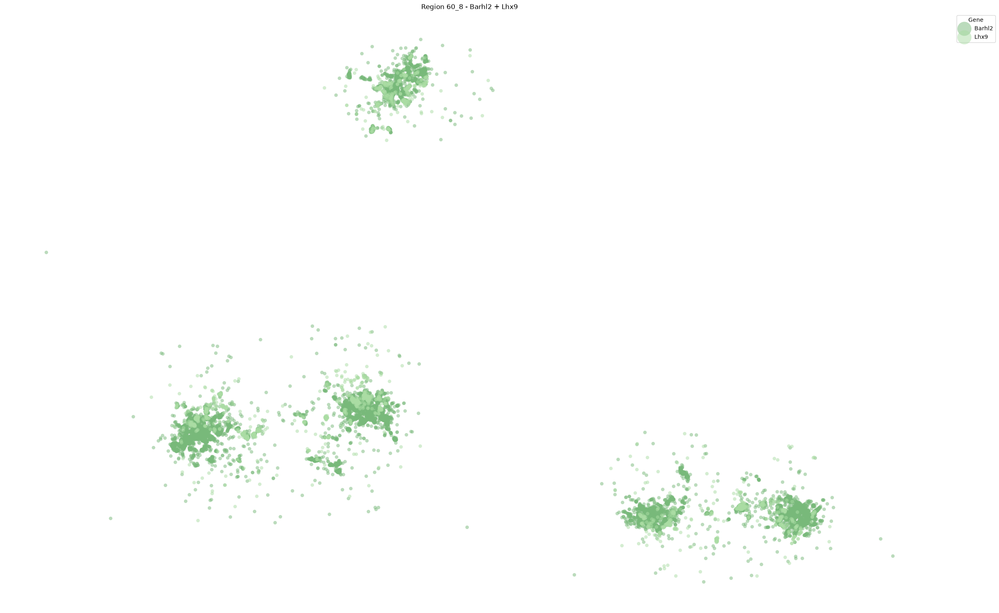

In [23]:
## dI1
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Barhl2", "Lhx9" ]

overlay_colors = {
    "Tubb3": 'k',
    "Barhl2": "#78B97A",
    "Lhx9": "#ABDDA4"
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

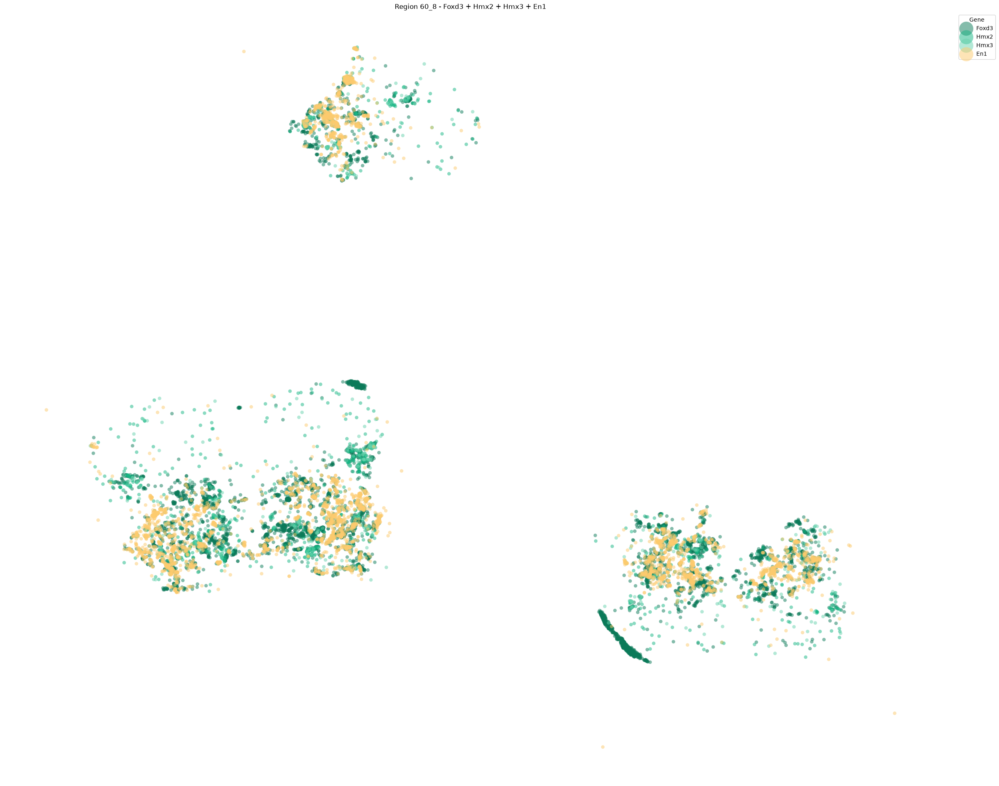

In [24]:
## dI2
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Foxd3", "Hmx2", "Hmx3", "En1"]

overlay_colors = {
    "Tubb3": 'k',
    "Foxd3": "#0B7A59",
    "Hmx2": "#17B684",
    "Hmx3": "#69D3AE",
    "En1": "#FDCB6E",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

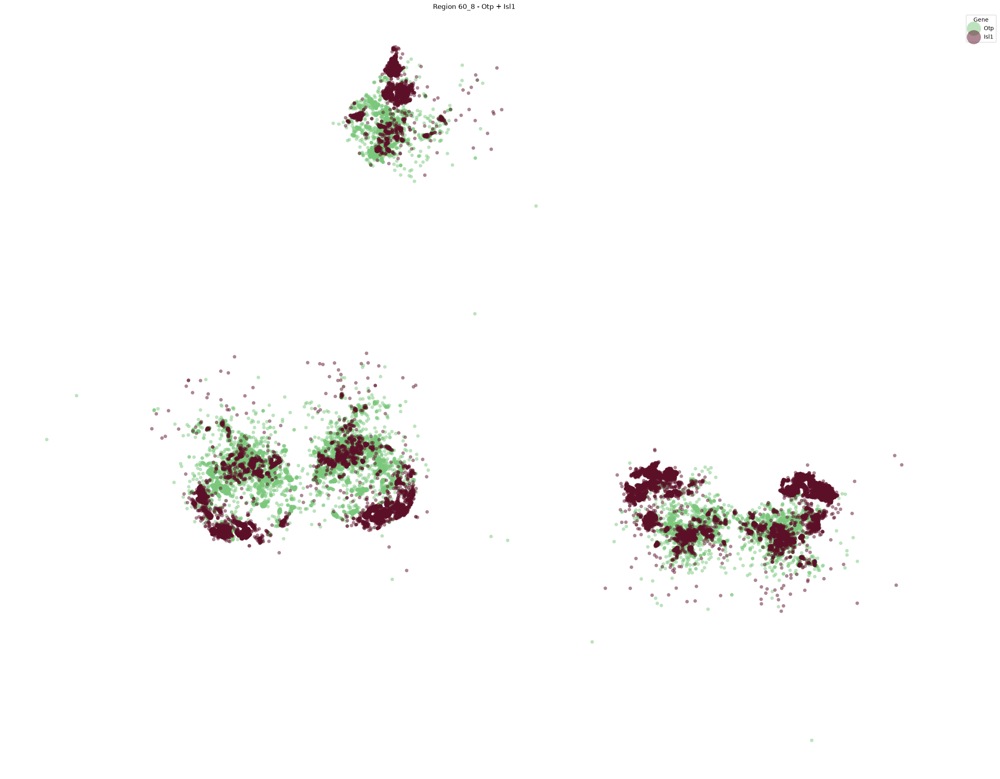

In [25]:
### dI3
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Otp", "Isl1"]

overlay_colors = {
    "Otp": "#7BC87C",
    "Isl1": "#5C1028"
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

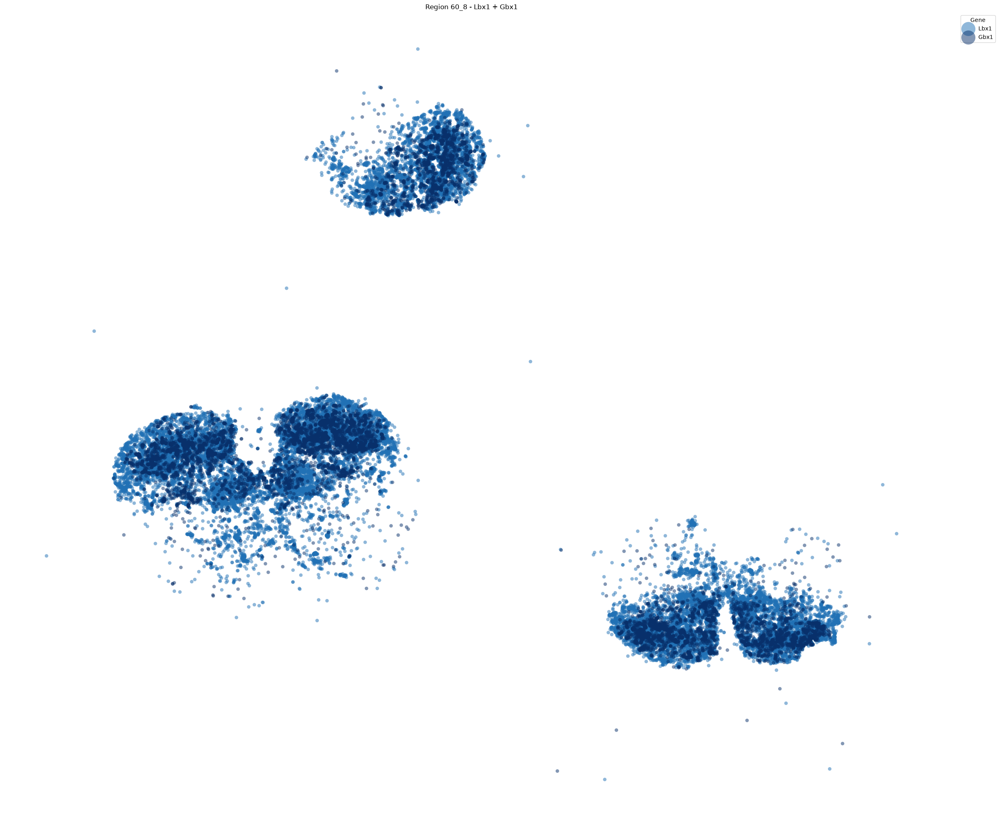

In [26]:
### dI4
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Lbx1", "Gbx1" ]

overlay_colors = {
    "Lbx1": "#2171B5",
    "Gbx1": "#08306B",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

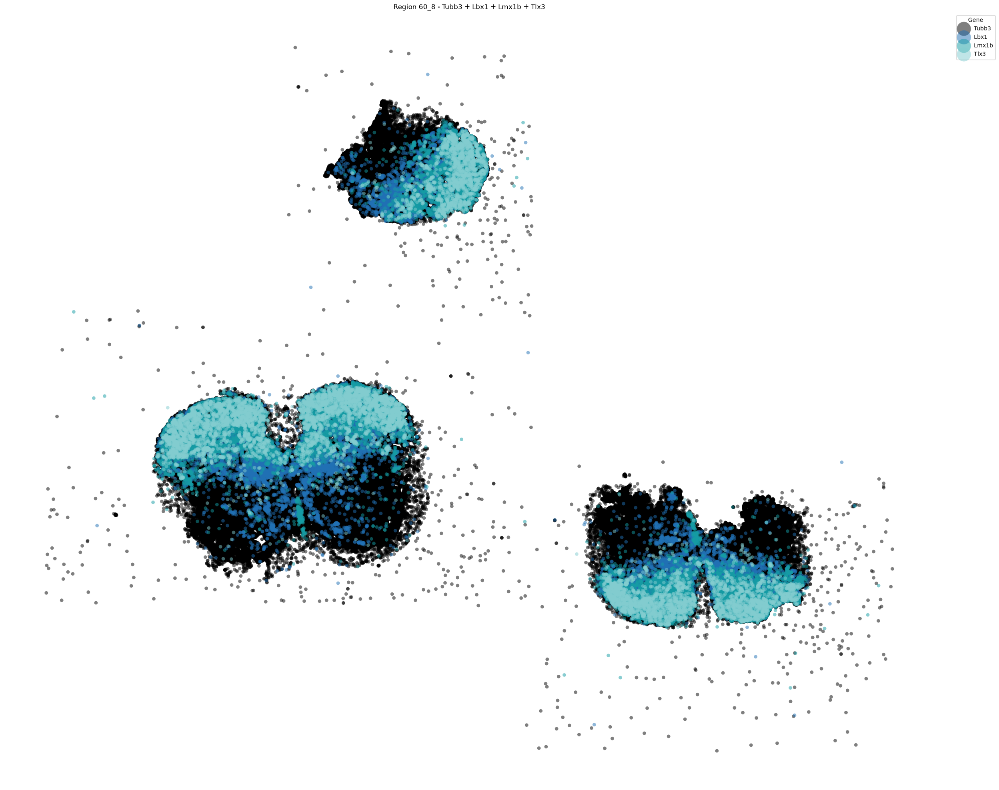

In [27]:
### dI5
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Tubb3", "Lbx1", "Lmx1b", "Tlx3"]

overlay_colors = {
    "Tubb3": 'k',
    "Lbx1": "#2171B5",
    "Lmx1b": "#159CA4",
    "Tlx3": "#83CDD0",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

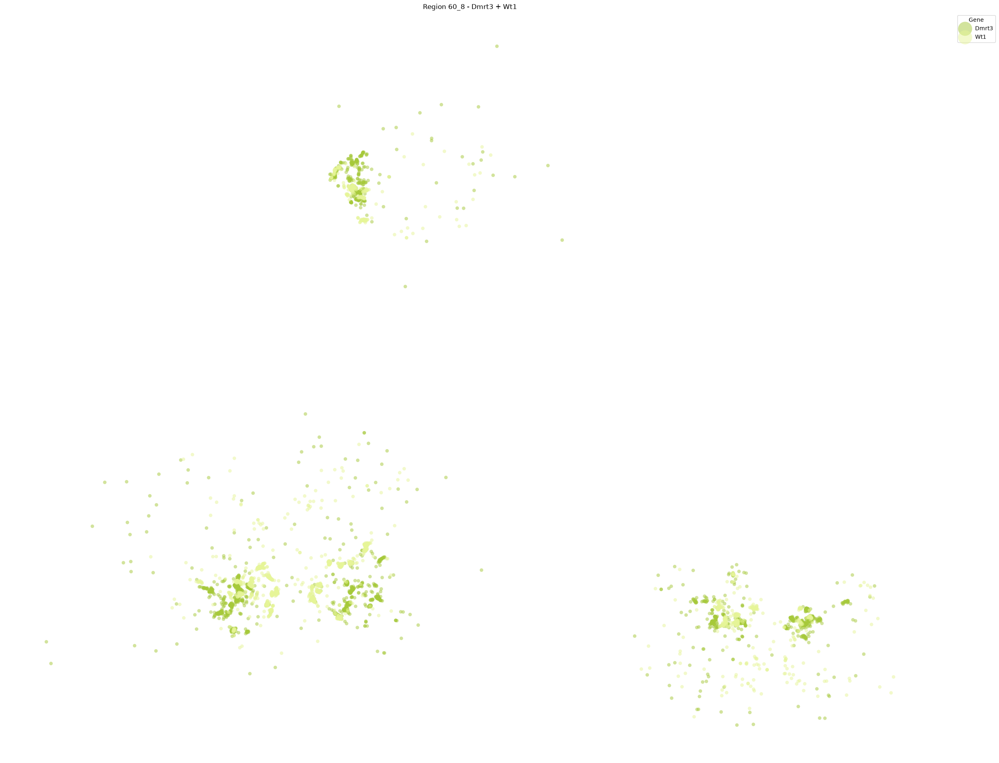

In [28]:
### dI6
### Overlay multiple transcripts on one spatial plot
# Add Lbx1

genes_to_overlay = ["Dmrt3", "Wt1"]

overlay_colors = {
    "Tubb3": 'k',
    "Dmrt3": "#A6C93A",
    "Wt1": "#E6F598",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

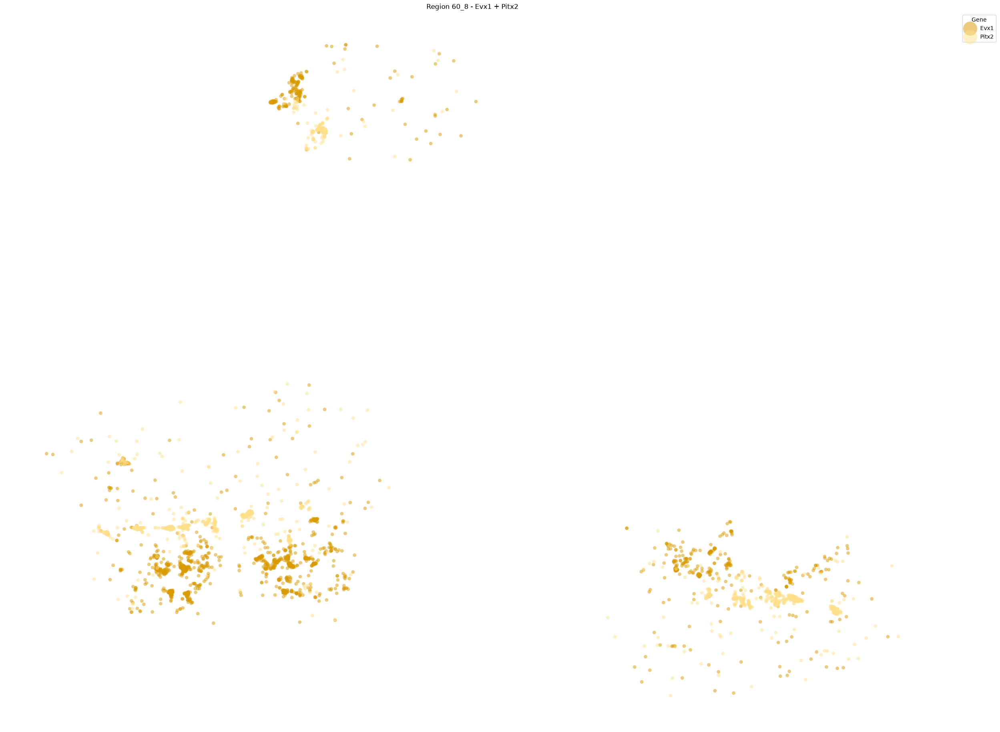

In [29]:
### V0
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Evx1", "Pitx2"]

overlay_colors = {
    "Evx1": "#D99A00",
    "Pitx2": "#FEE08B",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

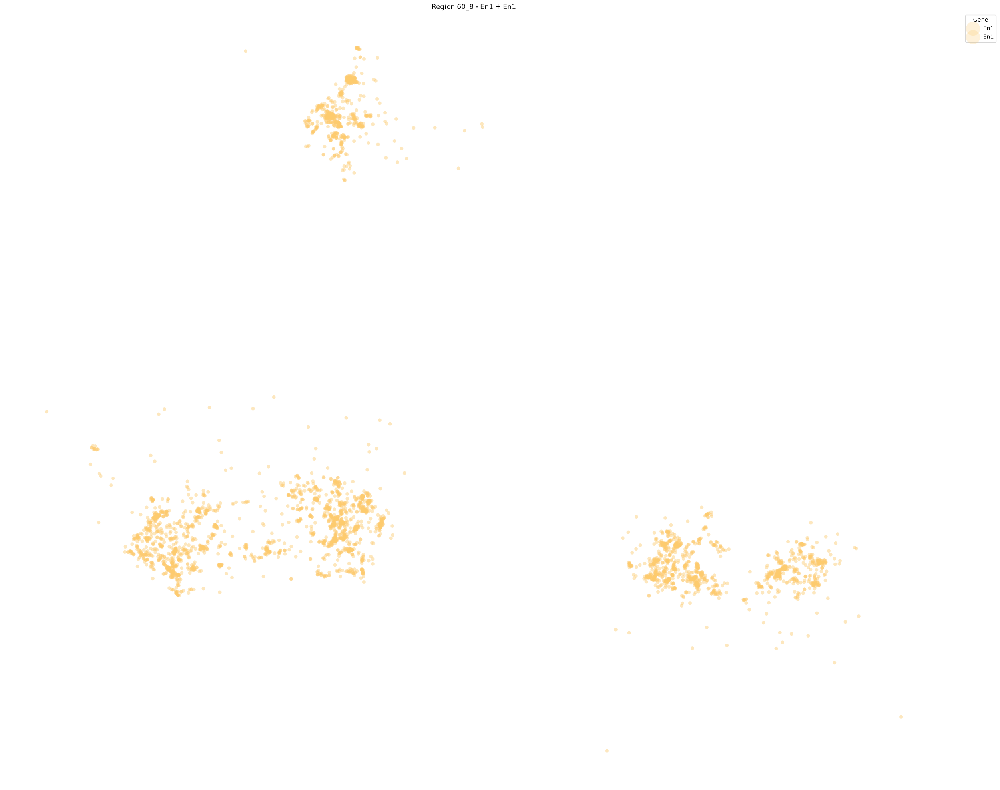

In [30]:
### V1
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["En1", "En1"]

overlay_colors = {
    "En1": "#FDCB6E",
    "En1": "#FDCB6E",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.25,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.svg"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

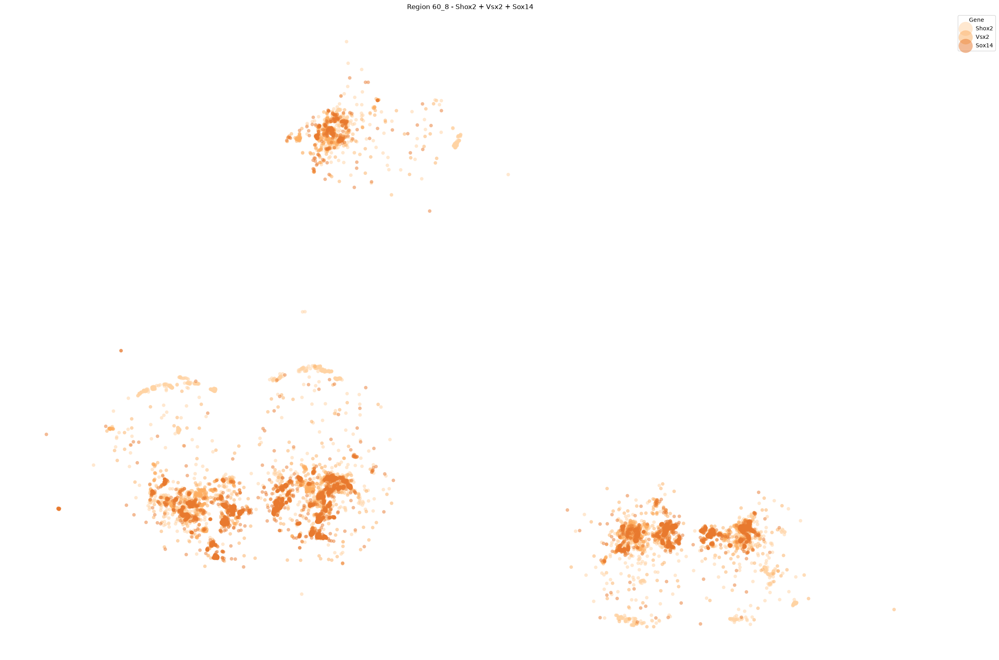

In [31]:
## V2a
### Overlay multiple transcripts on one spatial plot


genes_to_overlay = ["Shox2", "Vsx2", "Sox14"]

overlay_colors = {
    "Shox2": "#FFD3A3",
    "Vsx2": "#FDAE61",
    "Sox14": "#E8792E",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

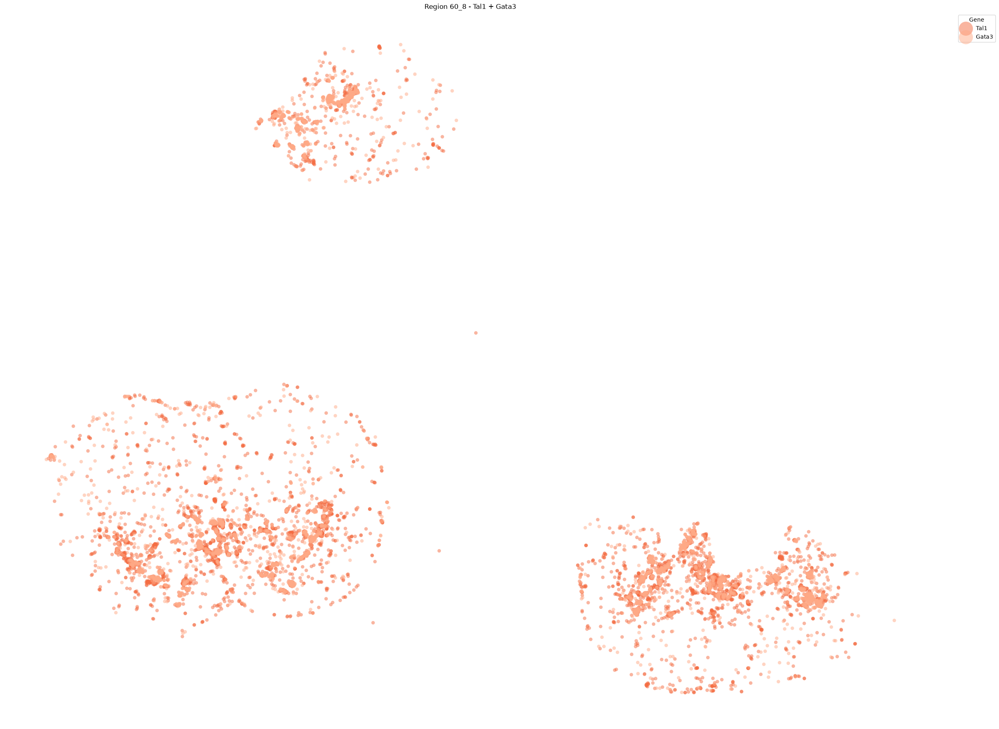

In [32]:
## V2b
### Overlay multiple transcripts on one spatial plot


genes_to_overlay = ["Tal1", "Gata3"]

overlay_colors = {
    "Mnx1": "#D94A2B",
    "Tal1": "#F46D43",
    "Gata3": "#FFAA87",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

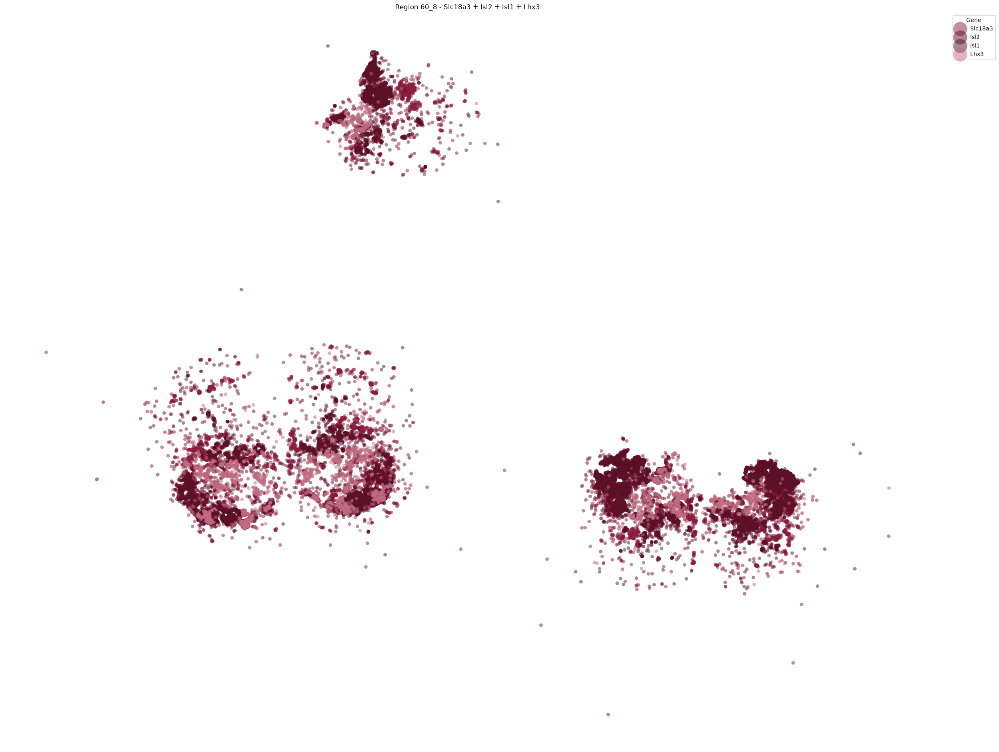

In [33]:
### MNs
### Overlay multiple transcripts on one spatial plot
# Chat and Slc18a3 have same pattern
# Mnx1 (Hb9) seems to also be in the LMC
# Foxp1 is everywhere

genes_to_overlay = ["Slc18a3", "Isl2", "Isl1" , "Lhx3"]

overlay_colors = {
    "Tubb3": 'k',
    "Isl1": "#5C1028",
    "Isl2": "#5C1028",
    "Lhx3": "#C06B82",
    "Chat": "#A6435F",
    "Slc18a3": "#8B1E3F",
    "Mnx1": "#FDCB6E",
}

fig, ax = plt.subplots(figsize=(25,25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.5,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.pdf"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

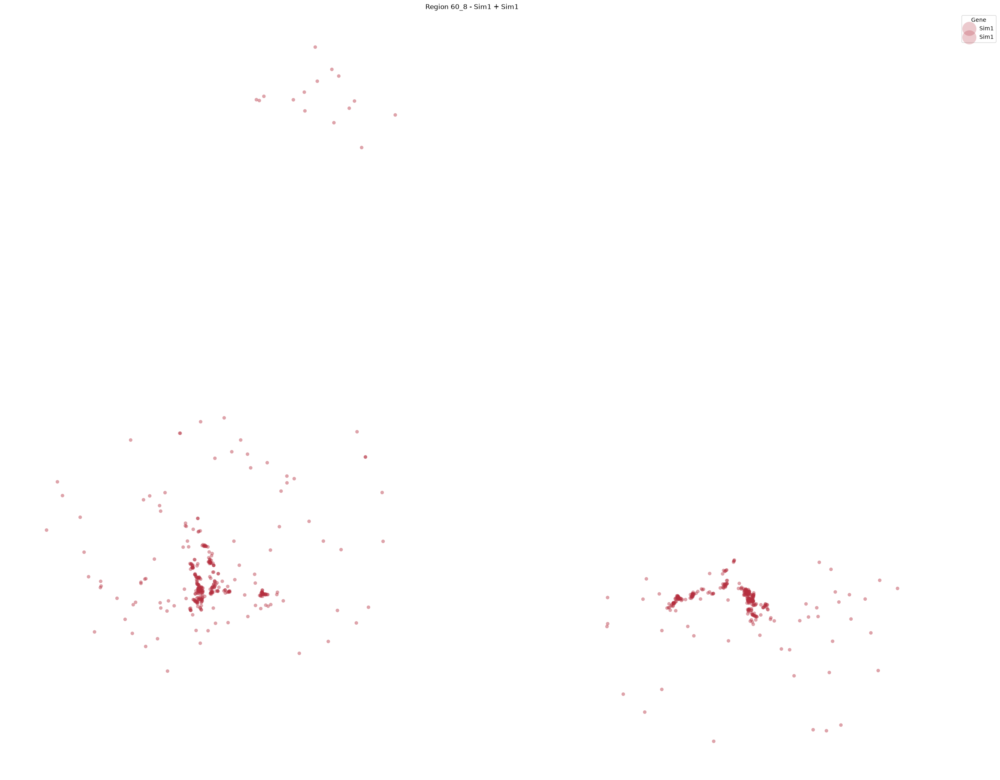

In [34]:
## V3
### Overlay multiple transcripts on one spatial plot

genes_to_overlay = ["Sim1", "Sim1"]

overlay_colors = {
    "Sim1": "#B52F3F",
    "Sim1": "#B52F3F",
}

fig, ax = plt.subplots(figsize=(25, 25))

for gene in genes_to_overlay:

    sub = transcripts[
        transcripts["feature_name"] == gene
    ]

    ax.scatter(
        sub["x"],
        sub["y"],
        s=40,
        color=overlay_colors[gene],
        label=gene,
        alpha=0.25,
        edgecolors="none",
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(
    f"{region} - " + " + ".join(genes_to_overlay)
)

ax.legend(
    title="Gene",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=4
)

plt.tight_layout()

fig.savefig(
    plot_dir / (
        f"{region.replace(' ', '_')}_"
        + "_".join(genes_to_overlay)
        + "_overlay.svg"
    ),
    bbox_inches="tight",
    dpi=600
)

plt.show()

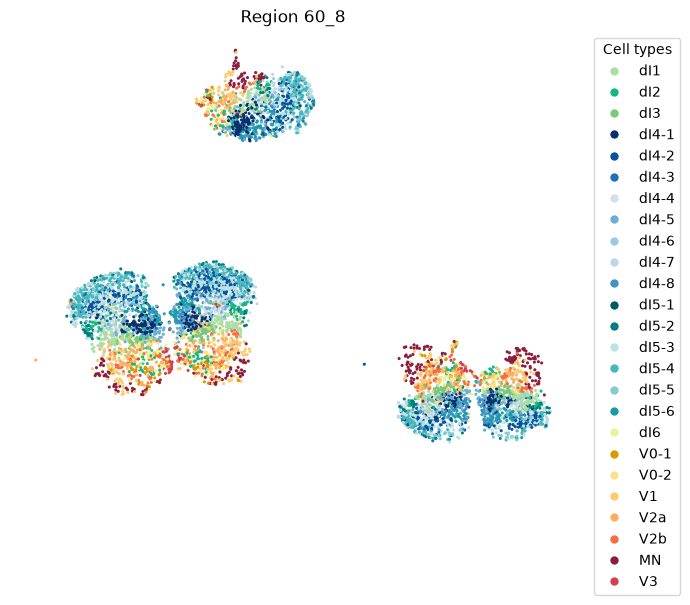

In [35]:
### Spatial plot of neuron types

sub = adata_neurons_SCNeuron_genes[
    adata_neurons_SCNeuron_genes.obs["region"] == region
].copy()

# Build plotting dataframe
plot_df = sub.obs[
    ["spatial_x", "spatial_y", "cell_type"]
].copy()

# Randomize individual cell plotting order
plot_df = plot_df.sample(
    frac=1,
    random_state=0
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    plot_df["spatial_x"],
    plot_df["spatial_y"],
    s=5,
    c=plot_df["cell_type"].map(xenium_config.cell_type_colors),
    edgecolors="none",
    rasterized=True,
)

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(region)

# Manual legend
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=xenium_config.cell_type_colors[cell_type],
        markeredgecolor="none",
        markersize=6,
        label=cell_type
    )
    for cell_type in sub.obs["cell_type"].cat.categories
    if cell_type in xenium_config.cell_type_colors
]

ax.legend(
    handles=legend_handles,
    title="Cell types",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1
)

plt.tight_layout()

# Save the figure
plot_dir = Path(overall_dir) / "Leiden"
plot_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    plot_dir / "Spatial_leiden_60_8.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

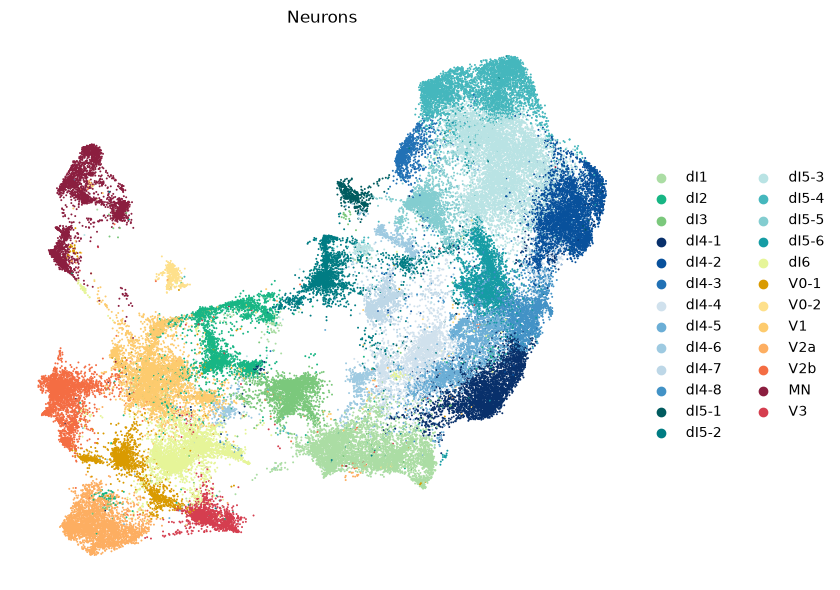

In [36]:
### UMAP with neuron type names

umap_plot_dir = Path(overall_dir) / "Leiden"

fig, ax = plt.subplots(figsize=(8.5, 6))

sc.pl.umap(
    adata_neurons_SCNeuron_genes,
    color='cell_type',
    layer="lognorm",
    cmap="viridis",
    frameon=False,
    ax=ax,
    show=False,
    title='Neurons',
    size=8)

# Rasterize the UMAP points
for collection in ax.collections:
    collection.set_rasterized(True)

plt.tight_layout()

fig.savefig(
    umap_plot_dir / "neuron_umap_leiden.pdf",
    dpi=600,
    bbox_inches="tight")

plt.show()
plt.close(fig)

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


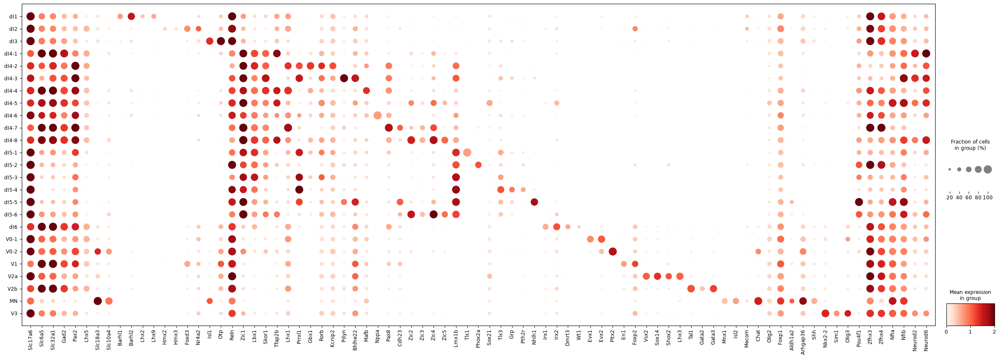

In [37]:
### Dotplot of neurons with all genes used for neuron clustering

dotplot_dir = Path(overall_dir) / "Leiden"
dp = sc.pl.dotplot(adata_neurons_SCNeuron_genes, var_names=xenium_config.select_genes, groupby="cell_type", layer="lognorm", standard_scale=None, figsize=(30,10), dendrogram=False, cmap="Reds", vmin=0, vmax=2, linewidth=0, return_fig=True)
dp.savefig(dotplot_dir / "neurons_reclustered_leiden_dotplot_neuronal_genes.svg", dpi=600, bbox_inches="tight")

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


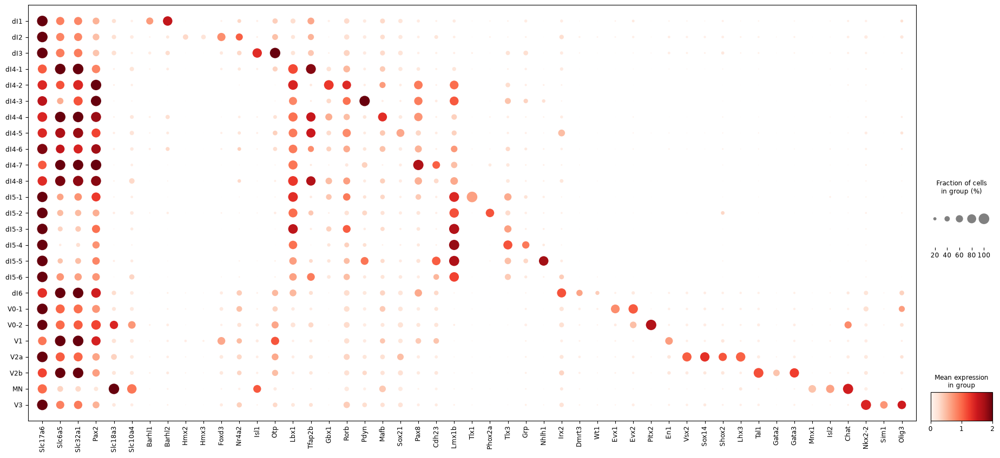

In [38]:
### Dotplot of neurons with selected genes

dotplot_dir = Path(overall_dir) / "Leiden"
dp = sc.pl.dotplot(adata_neurons_SCNeuron_genes, var_names=xenium_config.select_genes_Lora, groupby="cell_type", layer="lognorm", standard_scale=None, figsize=(23,10), dendrogram=False, cmap="Reds", vmin=0, vmax=2, linewidth=0, return_fig=True)
dp.savefig(dotplot_dir / "neurons_reclustered_leiden_dotplot_select_genes.svg", dpi=600, bbox_inches="tight")

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


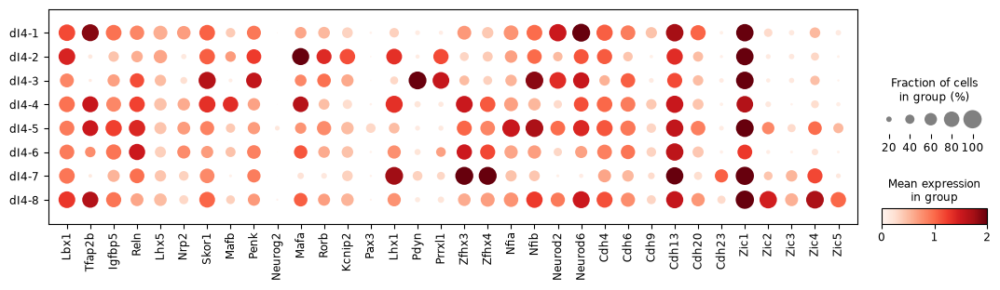

In [80]:
### dI4 dotplot

adata_dI4 = adata_neurons_SCNeuron_genes[
    adata_neurons_SCNeuron_genes.obs["cell_type"].astype(str).str.startswith("dI4")
].copy()

dotplot_dir = Path(overall_dir) / "Leiden"
dp = sc.pl.dotplot(adata_dI4, var_names=xenium_config.CLONE1_GENES, groupby="cell_type", layer="lognorm", standard_scale=None, figsize=(13,3), dendrogram=False, cmap="Reds", vmin=0, vmax=2, linewidth=0, return_fig=True)
dp.savefig(dotplot_dir / "di4_dotplot_select_genes.svg", dpi=600, bbox_inches="tight")

/localhome/sgobeil/tmp/ipykernel_2033452/2687399843.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(r"^(dI6|V1|V2a|V2b)", regex=True)
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


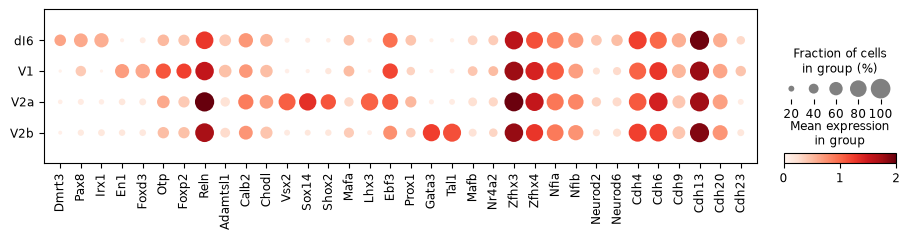

In [82]:
### dI6/V1/V2a/V2b dotplot

adata_dI6V1V2aV2b = adata_neurons_SCNeuron_genes[
    adata_neurons_SCNeuron_genes.obs["cell_type"]
    .astype(str)
    .str.contains(r"^(dI6|V1|V2a|V2b)", regex=True)
].copy()

dotplot_dir = Path(overall_dir) / "Leiden"
dp = sc.pl.dotplot(adata_dI6V1V2aV2b, var_names=xenium_config.CLONE4_GENES, groupby="cell_type", layer="lognorm", standard_scale=None, figsize=(11,2), dendrogram=False, cmap="Reds", vmin=0, vmax=2, linewidth=0, return_fig=True)
dp.savefig(dotplot_dir / "di6V1V2aV2b_dotplot_select_genes.svg", dpi=600, bbox_inches="tight")

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


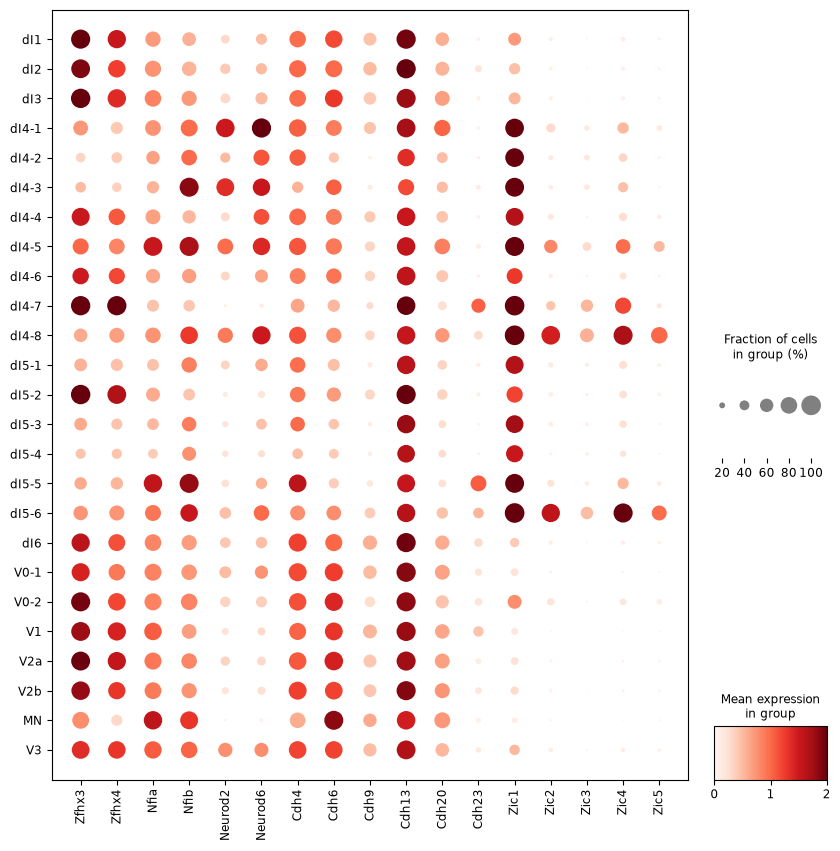

In [85]:
### TTFs, Cdhs, Zics

dotplot_dir = Path(overall_dir) / "Leiden"
dp = sc.pl.dotplot(adata_neurons_SCNeuron_genes, var_names=xenium_config.TTF_CDH_ZIC_GENES, groupby="cell_type", layer="lognorm", standard_scale=None, figsize=(10,10), dendrogram=False, cmap="Reds", vmin=0, vmax=2, linewidth=0, return_fig=True)
dp.savefig(dotplot_dir / "neurons_reclustered_leiden_dotplot_TTF_Cdh_Zics.svg", dpi=600, bbox_inches="tight")

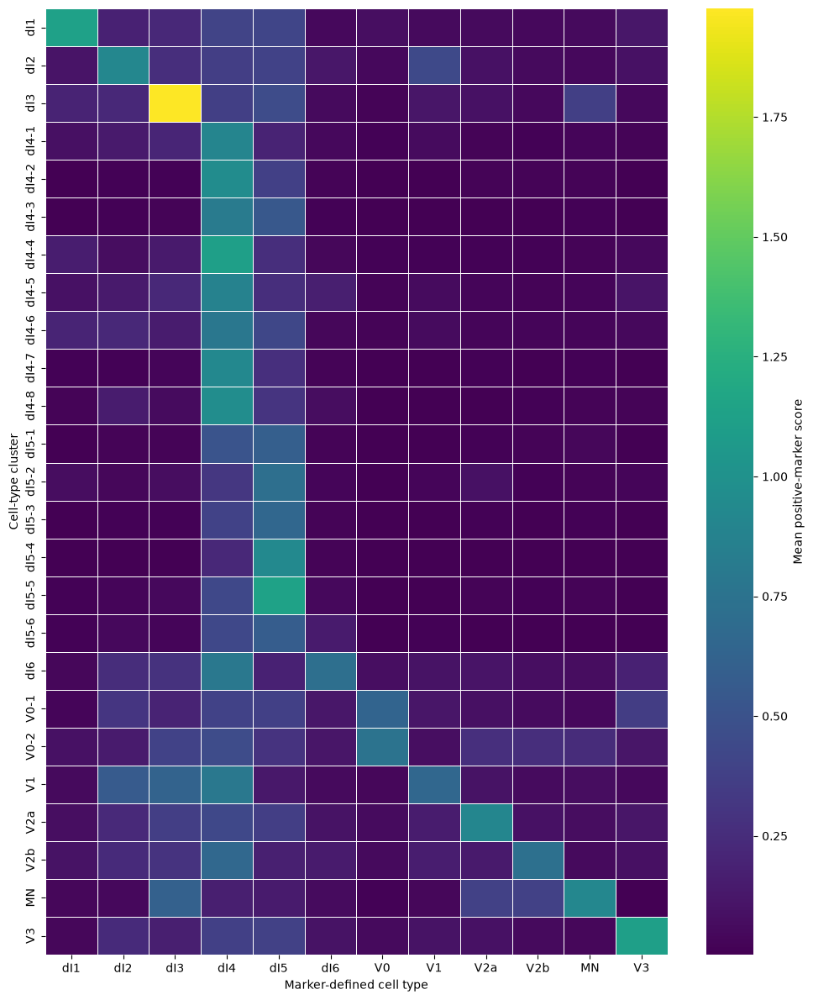

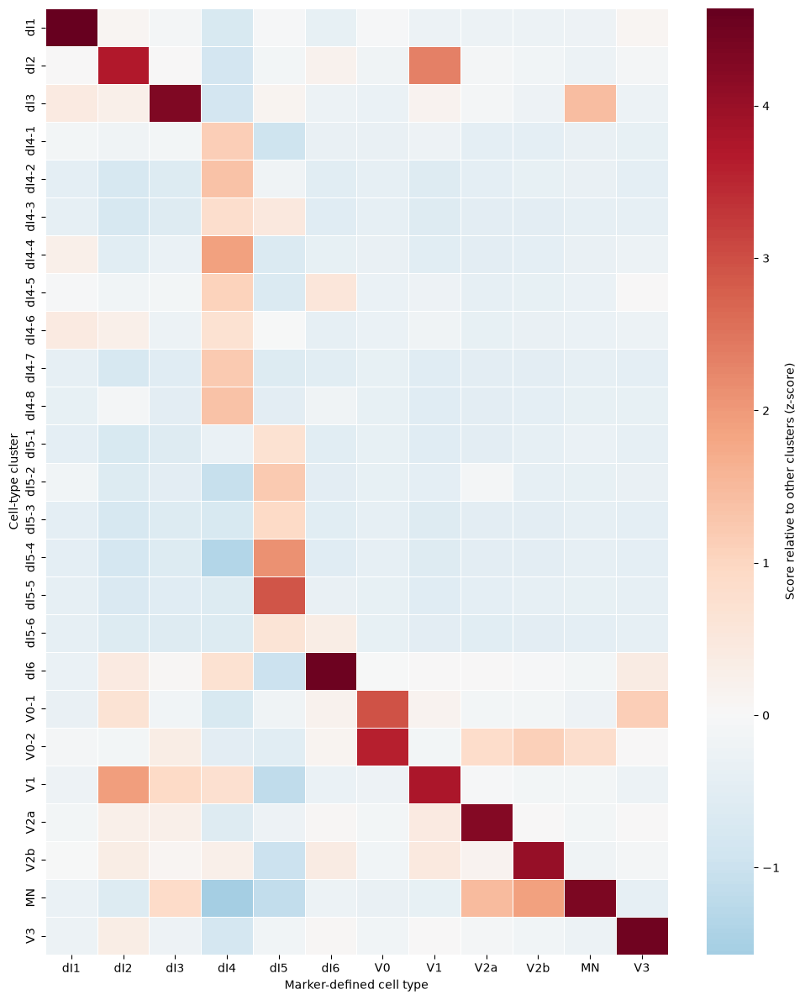

In [69]:
### Calculate mean positive-marker expression per cell

import xenium_config
import cardinal_class_markers

importlib.reload(xenium_config)
importlib.reload(cardinal_class_markers)

for cell_type, genes in cardinal_class_markers.class_markers.items():

    X = adata_neurons_SCNeuron_genes[
        :, genes
    ].layers["lognorm"]

    if sparse.issparse(X):
        score = np.asarray(X.mean(axis=1)).ravel()
    else:
        score = X.mean(axis=1)

    adata_neurons_SCNeuron_genes.obs[
        f"{cell_type}_score"
    ] = score

score_cols = [
    f"{cell_type}_score"
    for cell_type in cardinal_class_markers.class_markers.keys()
]

cluster_score_df = (
    adata_neurons_SCNeuron_genes.obs[
        ["cell_type"] + score_cols
    ]
    .groupby("cell_type", observed=True)
    .mean()
)

cluster_score_df.columns = [
    col.replace("_score", "")
    for col in cluster_score_df.columns
]

plt.figure(figsize=(10, 12))

sns.heatmap(
    cluster_score_df,
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={
        "label": "Mean positive-marker score"
    }
)

plt.xlabel("Marker-defined cell type")
plt.ylabel("Cell-type cluster")

plt.tight_layout()
plt.show()

cluster_score_z = (
    cluster_score_df
    - cluster_score_df.mean(axis=0)
) / cluster_score_df.std(axis=0)

plt.figure(figsize=(10, 12))

sns.heatmap(
    cluster_score_z,
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Score relative to other clusters (z-score)"
    }
)

plt.xlabel("Marker-defined cell type")
plt.ylabel("Cell-type cluster")

plt.tight_layout()
plt.show()

dI1: using ['Barhl1', 'Barhl2']
dI2: using ['Foxd3', 'Nr4a2']
dI3: using ['Isl1', 'Otp']
dI4: using ['Slc6a5', 'Slc32a1', 'Pax2', 'Tfap2b', 'Pdyn', 'Mafb', 'Pax8', 'Sox21', 'Gbx1', 'Rorb']
dI5: using ['Slc17a6', 'Lmx1b', 'Tlx3', 'Grp', 'Nhlh1', 'Phox2a', 'Grp', 'Nhlh1']
dI6: using ['Dmrt3', 'Wt1', 'Irx2']
V0: using ['Evx1', 'Evx2', 'Pitx2']
V1: using ['En1', 'Foxd3']
V2a: using ['Vsx2', 'Shox2', 'Sox14', 'Chat']
V2b: using ['Gata2', 'Gata3', 'Tal1', 'Chat']
MN: using ['Chat', 'Isl1', 'Isl2', 'Mnx1']
V3: using ['Sim1', 'Olig3']


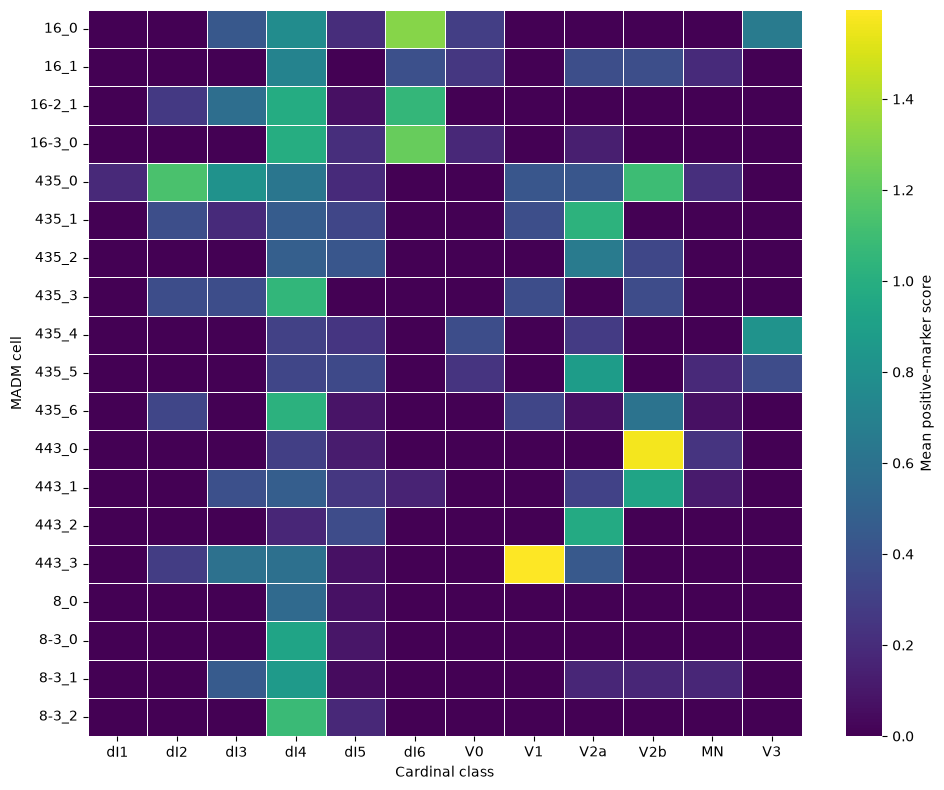

In [72]:
### Calculate cardinal-class scores for MADM cells

madm_score_cols = []

for cell_type, genes in cardinal_class_markers.class_markers.items():

    # Use exactly the genes present in BOTH datasets
    genes_present = [
        gene for gene in genes
        if gene in adata_neurons_SCNeuron_genes.var_names
        and gene in adata_madm_query.var_names
    ]

    print(f"{cell_type}: using {genes_present}")

    if len(genes_present) == 0:
        print(f"WARNING: no markers present for {cell_type}")
        continue

    X = adata_madm_query[
        :, genes_present
    ].layers["lognorm"]

    if sparse.issparse(X):
        score = np.asarray(X.mean(axis=1)).ravel()
    else:
        score = X.mean(axis=1)

    score_col = f"{cell_type}_score"

    adata_madm_query.obs[score_col] = score

    madm_score_cols.append(score_col)

### MADM cells x cardinal-class scores

madm_score_df = adata_madm_query.obs[
    madm_score_cols
].copy()

madm_score_df.columns = [
    col.replace("_score", "")
    for col in madm_score_df.columns
]

madm_score_df.index = adata_madm_query.obs["target_cell"].astype(str)

plt.figure(figsize=(10, 8))

sns.heatmap(
    madm_score_df,
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={
        "label": "Mean positive-marker score"
    }
)

plt.xlabel("Cardinal class")
plt.ylabel("MADM cell")

plt.tight_layout()
plt.show()

In [68]:
######################################################################################################################################################
### MADM Plots

In [162]:
# Custom display labels
MADM_LABELS = {
    "443_0": "Clone 3 Cell 4",
    "443_1": "Clone 3 Cell 3",
    "443_2": "Clone 3 Cell 2",
    "443_3": "Clone 3 Cell 1",
    
    "435_0": "Clone 4 Cell 6",
    "435_1": "Clone 4 Cell 3",
    "435_2": "Clone 4 Cell 2",
    "435_3": "Clone 4 Cell 1",
    "435_5": "Clone 4 Cell 4",
    "435_6": "Clone 4 Cell 5",

    "8_0": "Clone 1 Cell 4",
    "8-3_0": "Clone 1 Cell 1",
    "8-3_1": "Clone 1 Cell 2",
    "8-3_2": "Clone 1 Cell 3",

    "16_0": "Clone 2 Cell 1",
    "16_1": "Clone 2 Cell 2",
    "16-2_1": "Clone 2 Cell 3",
    "16-3_0": "Clone 2 Cell 4"}

# Custom display labels
MADM_LABELS_TYPE = {
    "443_0": "Clone 3 Cell 4 V2b",
    "443_1": "Clone 3 Cell 3 V2b",
    "443_2": "Clone 3 Cell 2 V2a",
    "443_3": "Clone 3 Cell 1 V1",
    
    "435_0": "Clone 4 Cell 6 V2b",
    "435_1": "Clone 4 Cell 3 V2a",
    "435_2": "Clone 4 Cell 2 V2a",
    "435_3": "Clone 4 Cell 1 V1",
    "435_5": "Clone 4 Cell 4 V2a",
    "435_6": "Clone 4 Cell 5 V2b",

    "8_0": "Clone 1 Cell 4 dI4-5",
    "8-3_0": "Clone 1 Cell 1 dI4-1",
    "8-3_1": "Clone 1 Cell 2 dI4-1",
    "8-3_2": "Clone 1 Cell 3 dI4-4",

    "16_0": "Clone 2 Cell 1 dI6",
    "16_1": "Clone 2 Cell 2 dI6",
    "16-2_1": "Clone 2 Cell 3 dI6",
    "16-3_0": "Clone 2 Cell 4 dI6"}

# Desired row order (using original cell IDs)
MADM_ORDER = [
    "8-3_0",
    "8-3_1",
    "8-3_2",
    "8_0",
    
    "16_0",
    "16_1",
    "16-2_1",
    "16-3_0",

    "443_3",
    "443_2",
    "443_1",
    "443_0",  
    
    "435_3",
    "435_2",
    "435_1",
    "435_5",
    "435_6",
    "435_0",
]

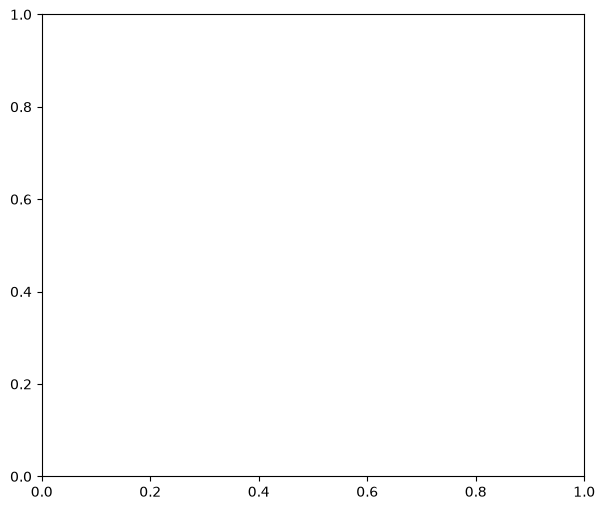

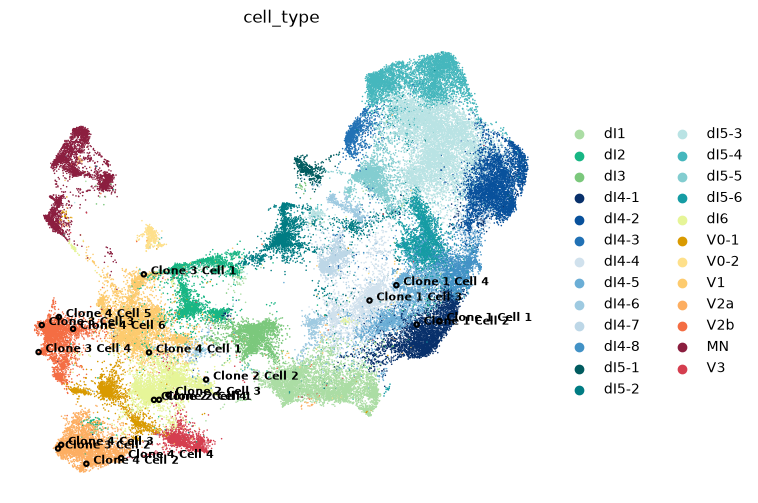

In [163]:
### NEURONS 
### UMAP with mapped MADM cells

madm_dir = Path(overall_dir) / "MADM"
madm_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 6))

# MADM cells to exclude (original target_cell IDs)
EXCLUDE_MADM = ["435_4"]


fig, ax = plt.subplots(figsize=(7, 6))

sc.pl.umap(
    adata_neurons_SCNeuron_genes,
    color="cell_type",
    frameon=False,
    ax=ax,
    show=False,
    size=5
)

# Rasterize only low-zorder artists (i.e. the background UMAP points)
ax.set_rasterization_zorder(5)

# Plot MADM cells
madm_umap = adata_madm_query.obsm["X_umap"]

for i in range(adata_madm_query.n_obs):

    cell_id = str(adata_madm_query.obs.iloc[i]["target_cell"])

    # Skip excluded cells
    if cell_id in EXCLUDE_MADM:
        continue

    x, y = madm_umap[i]

    ax.scatter(
        x,
        y,
        s=10,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        zorder=10
    )

    # Use custom label, or original ID if not specified
    display_label = MADM_LABELS.get(cell_id, cell_id)

    ax.annotate(
        display_label,
        (x, y),
        xytext=(5, 0),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        zorder=11
    )

fig.savefig(
    madm_dir / "neuron_umap_leiden_with_madm.pdf",
    dpi=600,
    bbox_inches="tight")

plt.show()
plt.close(fig)

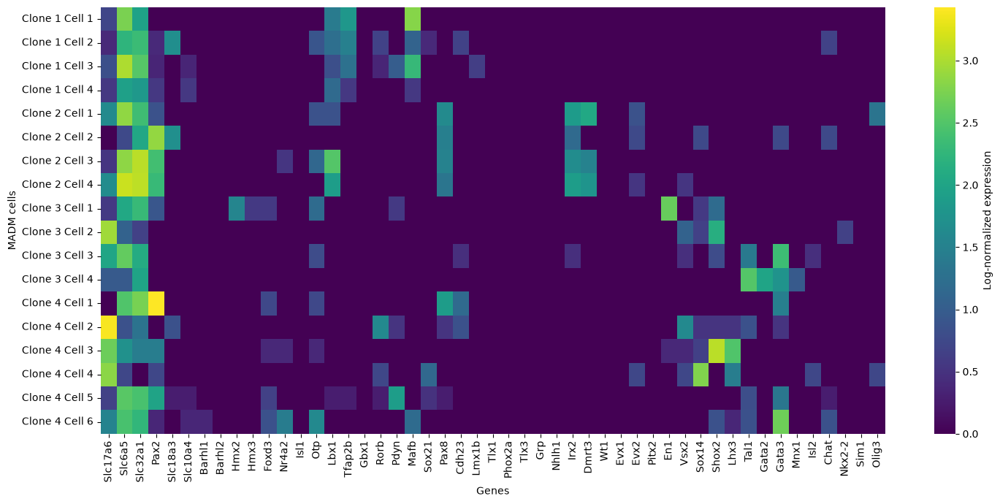

In [115]:
### Heatmap of MADM cell gene expression

# Same genes and same order as the cluster dotplot
genes = xenium_config.select_genes

# MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

madm_heatmap_df = pd.DataFrame(
    X.T,
    index=genes,
    columns=adata_madm_query.obs["target_cell"].astype(str).to_numpy()
)

madm_heatmap_df = madm_heatmap_df.loc[xenium_config.select_genes_Lora]
madm_heatmap_df = madm_heatmap_df.T

# NEW: Reorder rows
madm_heatmap_df = madm_heatmap_df.reindex(MADM_ORDER)

# NEW: Replace original cell IDs with display labels
madm_heatmap_df.index = [
    MADM_LABELS.get(cell, cell)
    for cell in madm_heatmap_df.index
]

# Plot
fig, ax = plt.subplots(figsize=(15, 7))

sns.heatmap(
    madm_heatmap_df,
    cmap="viridis",
    cbar_kws={"label": "Log-normalized expression"},
    ax=ax
)

ax.set_xlabel("Genes")
ax.set_ylabel("MADM cells")

plt.tight_layout()

fig.savefig(
    madm_dir / "madm_heatmap.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

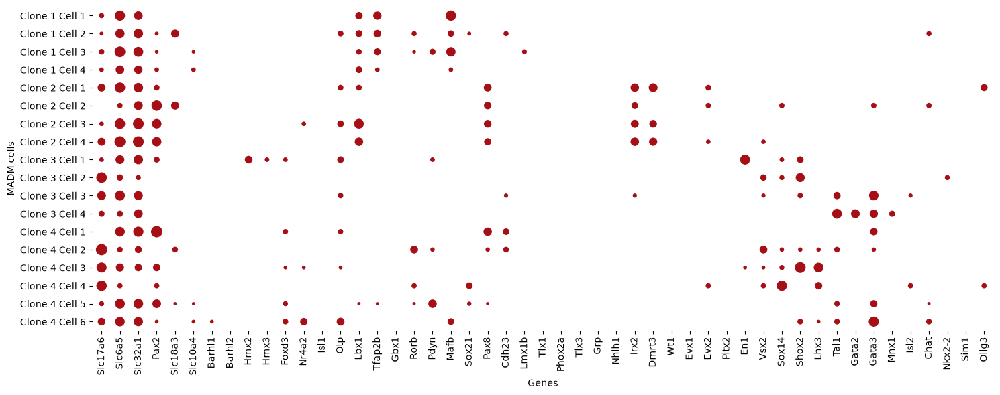

In [116]:
### Dotplot of MADM single-cell gene expression with all genes from neuron dotplot
# Custom display labels

# Same genes and same order as the cluster dotplot
genes = xenium_config.select_genes

# MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()


# Convert expression matrix to long format
madm_dotplot_df = (
    madm_heatmap_df
    .reset_index(names="Cell")
    .melt(
        id_vars="Cell",
        var_name="Gene",
        value_name="Expression"
    )
)

# Preserve gene order
gene_order = list(madm_heatmap_df.columns)

# Correctly assign cell positions
# pd.melt() arranges values gene by gene
madm_dotplot_df["Cell_index"] = np.tile(
    np.arange(len(madm_heatmap_df)),
    len(gene_order)
)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes

# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

# Plot
fig, ax = plt.subplots(figsize=(15, 6))

max_expr = madm_dotplot_df["Expression"].max()

ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    color="#A50F15",
    edgecolors="none"
)

ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

ax.set_yticks(np.arange(len(madm_heatmap_df)))
ax.set_yticklabels(madm_heatmap_df.index)

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_heatmap_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("MADM cells")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "madm_dotplot.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

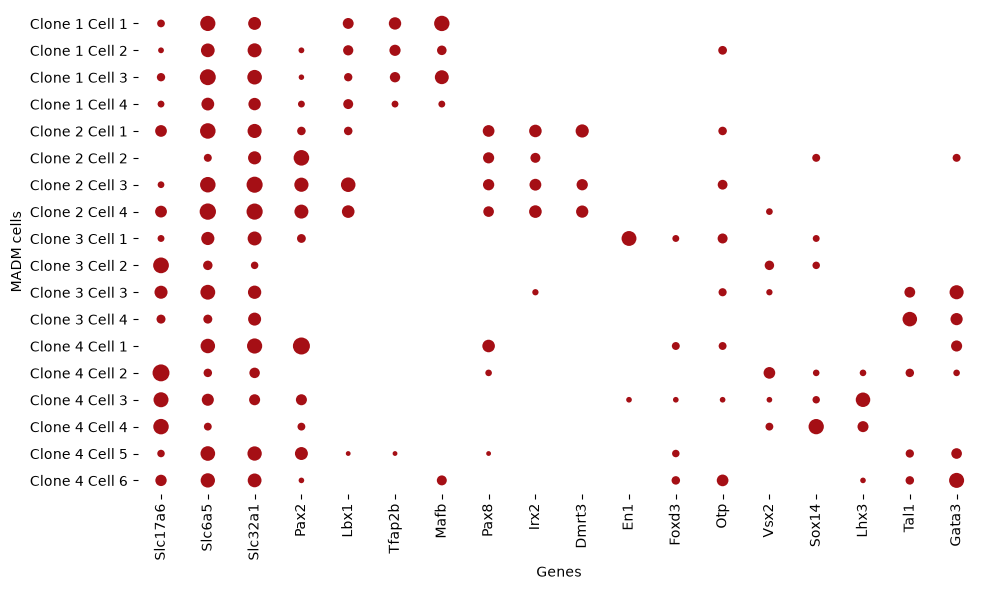

In [137]:
### Dotplot of MADM single-cell gene expression with genes relevant to clone classes

MADM_GENES = xenium_config.MADM_GENES.copy()
    

# Select genes that are present in the dataset
genes = [g for g in MADM_GENES if g in adata_madm_query.var_names]

missing_genes = [g for g in MADM_GENES if g not in adata_madm_query.var_names]
if missing_genes:
    print("Genes not found:", missing_genes)

# Extract MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

# Create new expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)

# Reorder cells using original IDs
missing_cells = [
    cell for cell in MADM_ORDER
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]

# Convert expression matrix into dotplot format
# Use numeric row positions to handle repeated labels
madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]

# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes

# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

max_expr = madm_dotplot_df["Expression"].max()

ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    color="#A50F15",
    edgecolors="none"
)

# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("MADM cells")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "madm_dotplot.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

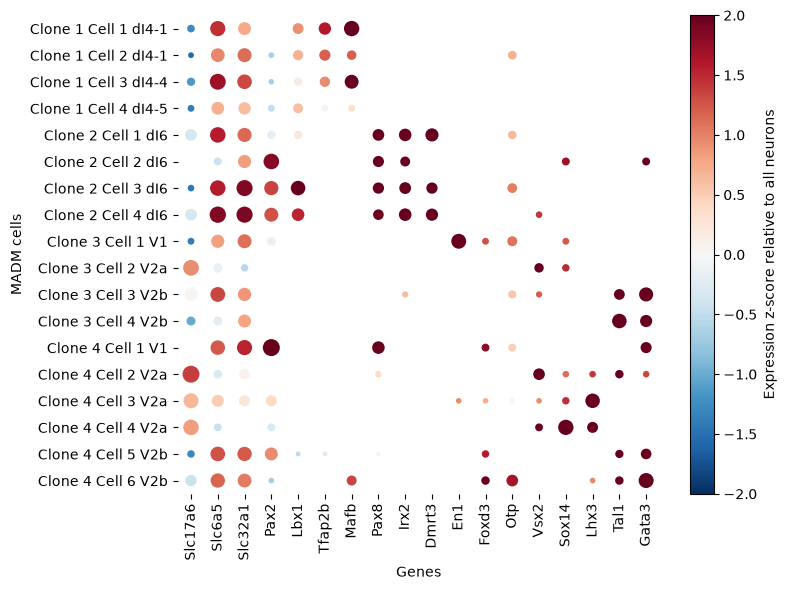

In [138]:
### Calculate MADM gene z-scores relative to all Xenium neurons

# Reference expression: all Xenium neurons
X_ref = adata_neurons_SCNeuron_genes[:, genes].layers["lognorm"]

if sparse.issparse(X_ref):
    X_ref = X_ref.toarray()

# Mean and SD of each gene across ALL reference neurons
ref_mean = X_ref.mean(axis=0)
ref_std = X_ref.std(axis=0)

# Avoid division by zero
ref_std[ref_std == 0] = 1


# MADM expression
X_madm = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X_madm):
    X_madm = X_madm.toarray()


# Z-score MADM cells relative to reference neurons
X_madm_z = (X_madm - ref_mean) / ref_std


# DataFrame
madm_zscore_df = pd.DataFrame(
    X_madm_z,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)

# Preserve MADM cell order
ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in madm_zscore_df.index
]

madm_zscore_df = madm_zscore_df.loc[ordered_cells]

### Convert expression and z-score matrices to dotplot format

madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]


madm_zscore_long = (
    madm_zscore_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_zscore_long.columns = [
    "Cell_index",
    "Gene",
    "Zscore"
]

madm_dotplot_df["Zscore"] = madm_zscore_long["Zscore"]


# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes


# Remove genes with zero detected expression in the MADM cell
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

fig, ax = plt.subplots(figsize=(8, 6))

max_expr = madm_dotplot_df["Expression"].max()

scatter = ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    c=madm_dotplot_df["Zscore"],
    cmap="RdBu_r",
    vmin=-2,
    vmax=2,
    edgecolors="none"
)

# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("MADM cells")

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Expression z-score relative to all neurons")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "madm_dotplot_reference_zscore.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

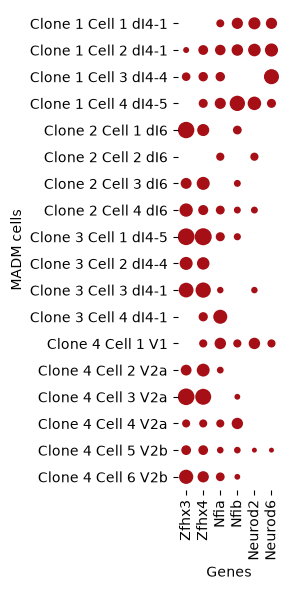

In [95]:
### Dotplot of MADM single-cell gene expression with TTFs

TTFs = [
    'Zfhx3',
    'Zfhx4',
    'Nfia',
    'Nfib',
    'Neurod2',
    'Neurod6',
]
    

# Select genes that are present in the dataset
genes = [g for g in TTFs if g in adata_madm_query.var_names]

missing_genes = [g for g in TTFs if g not in adata_madm_query.var_names]
if missing_genes:
    print("Genes not found:", missing_genes)

# Extract MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

# Create new expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)

# Reorder cells using original IDs
missing_cells = [
    cell for cell in MADM_ORDER
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]

# Convert expression matrix into dotplot format
# Use numeric row positions to handle repeated labels
madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]

# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes

# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

# Plot
fig, ax = plt.subplots(figsize=(3, 6))

max_expr = madm_dotplot_df["Expression"].max()

ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    color="#A50F15",
    edgecolors="none"
)

# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("MADM cells")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "madm_TTFs.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

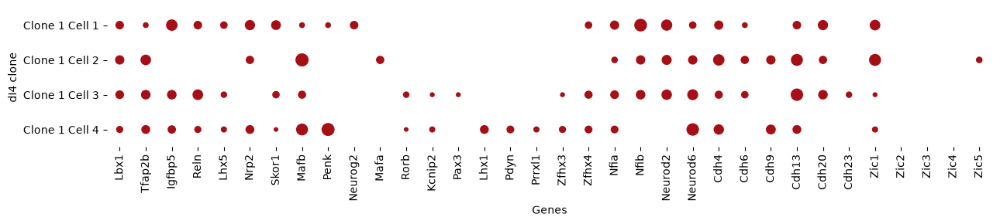

In [77]:
### dI4 clone dotplot (Clone 1)

MADM_CELLS_TO_PLOT = [
    "8_0",
    "8-3_0",
    "8-3_1",
    "8-3_2",
]
    
CLONE1_GENES = xenium_config.CLONE1_GENES.copy()

# Select genes that are present in the dataset
genes = [g for g in CLONE1_GENES if g in adata_madm_query.var_names]

missing_genes = [g for g in CLONE1_GENES if g not in adata_madm_query.var_names]
if missing_genes:
    print("Genes not found:", missing_genes)

# Extract MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

# Create new expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)

# Reorder cells using original IDs
missing_cells = [
    cell for cell in MADM_ORDER
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

# Select only desired cells
ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]

# Convert expression matrix into dotplot format
# Use numeric row positions to handle repeated labels
madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]

# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes

# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

# Plot
fig, ax = plt.subplots(figsize=(13,3))

max_expr = madm_dotplot_df["Expression"].max()

ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    color="#A50F15",
    edgecolors="none"
)

# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("dI4 clone")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "Clone1_dI4.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

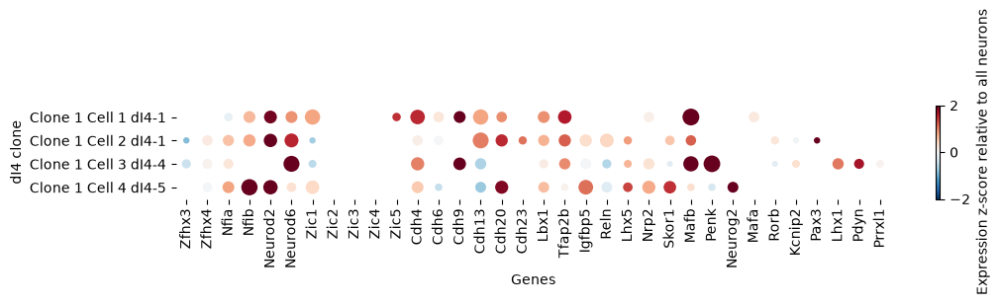

In [160]:
### dI4 clone z-score dotplot (Clone 1)
### Dot size = MADM log-normalized expression
### Dot color = z-score relative to all reference neurons

MADM_CELLS_TO_PLOT = [
    "8_0",
    "8-3_0",
    "8-3_1",
    "8-3_2",
]

CLONE1_GENES = xenium_config.CLONE1_GENES.copy()

# Select genes present in BOTH MADM and neuronal reference datasets
genes = [
    g for g in CLONE1_GENES
    if g in adata_madm_query.var_names
    and g in adata_neurons_SCNeuron_genes.var_names
]

missing_genes = [
    g for g in CLONE1_GENES
    if g not in adata_madm_query.var_names
    or g not in adata_neurons_SCNeuron_genes.var_names
]

if missing_genes:
    print("Genes not found:", missing_genes)


### Reference mean and SD across all neurons

X_ref = adata_neurons_SCNeuron_genes[:, genes].layers["lognorm"]

if sparse.issparse(X_ref):
    X_ref = X_ref.toarray()

ref_mean = X_ref.mean(axis=0)
ref_std = X_ref.std(axis=0)

# Avoid division by zero
ref_std[ref_std == 0] = 1


### Extract MADM log-normalized expression

X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()


# Expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


# MADM z-scores relative to all reference neurons
X_z = (X - ref_mean) / ref_std

madm_zscore_df = pd.DataFrame(
    X_z,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


### Select and order desired MADM cells

missing_cells = [
    cell for cell in MADM_CELLS_TO_PLOT
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]
madm_zscore_df = madm_zscore_df.loc[ordered_cells]


### Convert to dotplot format

madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]


madm_zscore_long = (
    madm_zscore_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_zscore_long.columns = [
    "Cell_index",
    "Gene",
    "Zscore"
]

madm_dotplot_df["Zscore"] = madm_zscore_long["Zscore"]


# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes


# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()


### Plot

fig, ax = plt.subplots(figsize=(11, 2.2))

max_expr = madm_dotplot_df["Expression"].max()

scatter = ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    c=madm_dotplot_df["Zscore"],
    cmap="RdBu_r",
    vmin=-2,
    vmax=2,
    edgecolors="none"
)


# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)


# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("dI4 clone")


# Z-score colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Expression z-score relative to all neurons")


sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "Clone1_dI4_zscore.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

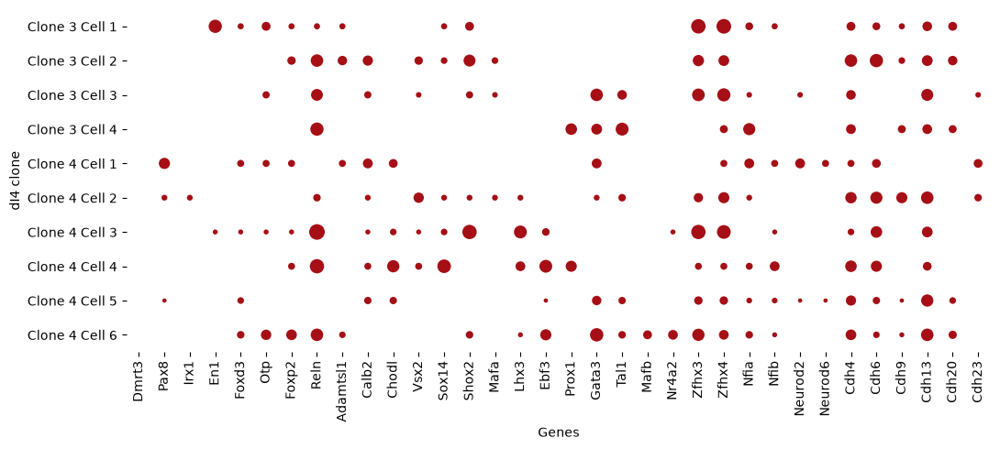

In [108]:
### V2a/V2b/V1 clone dotplot (Clones 3 and 4)

MADM_CELLS_TO_PLOT = [
    "435_0",
    "435_1",
    "435_2",
    "435_3",
    "435_5",
    "435_6",
    "443_0",
    "443_1",
    "443_2",
    "443_3"]

CLONE4_GENES = xenium_config.CLONE4_GENES.copy() 

# Select genes that are present in the dataset
genes = [g for g in CLONE4_GENES if g in adata_madm_query.var_names]

missing_genes = [g for g in CLONE4_GENES if g not in adata_madm_query.var_names]
if missing_genes:
    print("Genes not found:", missing_genes)

# Extract MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

# Create new expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)

# Reorder cells using original IDs
missing_cells = [
    cell for cell in MADM_ORDER
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

# Select only desired cells
ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]

# Convert expression matrix into dotplot format
# Use numeric row positions to handle repeated labels
madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]

# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes

# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

# Plot
fig, ax = plt.subplots(figsize=(11,5))

max_expr = madm_dotplot_df["Expression"].max()

ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    color="#A50F15",
    edgecolors="none"
)

# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("dI4 clone")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "Clone4_V2aV2bV1.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

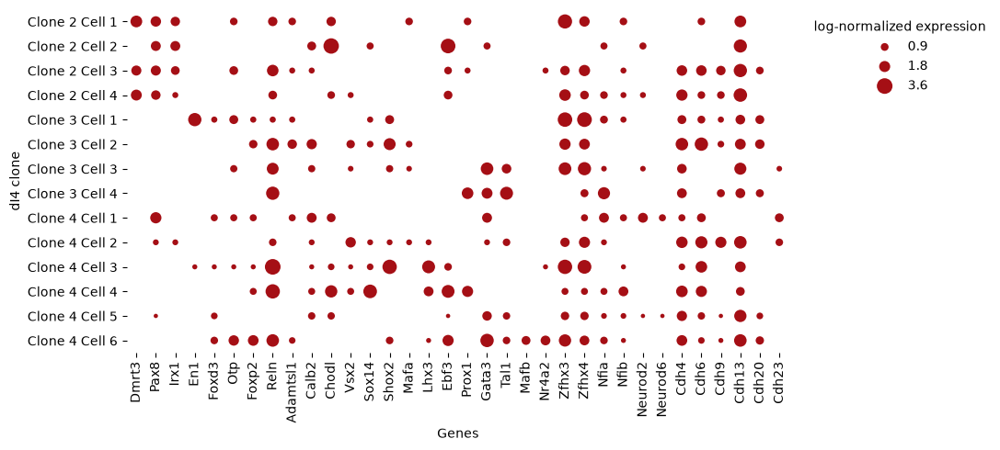

In [164]:
### V2a/V2b/V1 clone dotplot (Clones 2, 3, and 4)

MADM_CELLS_TO_PLOT = [
    "16_0",
    "16_1",
    "16-2_1",
    "16-3_0",
    "435_0",
    "435_1",
    "435_2",
    "435_3",
    "435_5",
    "435_6",
    "443_0",
    "443_1",
    "443_2",
    "443_3"]
    
CLONE4_GENES = xenium_config.CLONE4_GENES.copy() 
    

# Select genes that are present in the dataset
genes = [g for g in CLONE4_GENES if g in adata_madm_query.var_names]

missing_genes = [g for g in CLONE4_GENES if g not in adata_madm_query.var_names]
if missing_genes:
    print("Genes not found:", missing_genes)

# Extract MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

# Create new expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)

# Reorder cells using original IDs
missing_cells = [
    cell for cell in MADM_ORDER
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

# Select only desired cells
ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]

# Convert expression matrix into dotplot format
# Use numeric row positions to handle repeated labels
madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]

# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes

# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()

# Plot
fig, ax = plt.subplots(figsize=(11,5))

max_expr = madm_dotplot_df["Expression"].max()

ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    color="#A50F15",
    edgecolors="none"
)

# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)

# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("dI4 clone")

sns.despine(ax=ax, left=True, bottom=True)

# Dot size legend
size_values = [
    max_expr * 0.25,
    max_expr * 0.50,
    max_expr * 1.00
]

size_handles = [
    plt.scatter(
        [],
        [],
        s=value / max_expr * 150,
        color="#A50F15",
        edgecolors="none",
        label=f"{value:.1f}"
    )
    for value in size_values
]

ax.legend(
    handles=size_handles,
    title="log-normalized expression",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()

fig.savefig(
    madm_dir / "Clone2-4_dI6V1V2aV2b.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

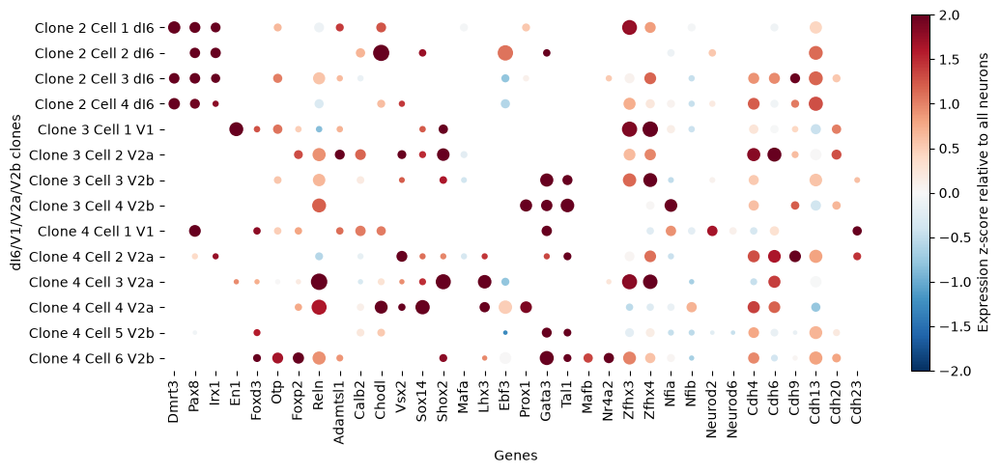

In [145]:
### V2a/V2b/V1 clone z-score dotplot (Clones 2, 3, and 4)
### Dot size = MADM log-normalized expression
### Dot color = z-score relative to all reference neurons

MADM_CELLS_TO_PLOT = [
    "16_0",
    "16_1",
    "16-2_1",
    "16-3_0",
    "435_0",
    "435_1",
    "435_2",
    "435_3",
    "435_5",
    "435_6",
    "443_0",
    "443_1",
    "443_2",
    "443_3"
]

CLONE4_GENES = xenium_config.CLONE4_GENES.copy()


# Select genes present in BOTH MADM and neuronal reference datasets
genes = [
    g for g in CLONE4_GENES
    if g in adata_madm_query.var_names
    and g in adata_neurons_SCNeuron_genes.var_names
]

missing_genes = [
    g for g in CLONE4_GENES
    if g not in adata_madm_query.var_names
    or g not in adata_neurons_SCNeuron_genes.var_names
]

if missing_genes:
    print("Genes not found:", missing_genes)


### Reference mean and SD across all neurons

X_ref = adata_neurons_SCNeuron_genes[:, genes].layers["lognorm"]

if sparse.issparse(X_ref):
    X_ref = X_ref.toarray()

ref_mean = X_ref.mean(axis=0)
ref_std = X_ref.std(axis=0)

# Avoid division by zero
ref_std[ref_std == 0] = 1


### Extract MADM log-normalized expression

X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()


# Create MADM expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


# Calculate MADM z-scores relative to all reference neurons
X_z = (X - ref_mean) / ref_std

madm_zscore_df = pd.DataFrame(
    X_z,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


### Select and order desired cells

missing_cells = [
    cell for cell in MADM_CELLS_TO_PLOT
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]
madm_zscore_df = madm_zscore_df.loc[ordered_cells]


### Convert expression matrix into dotplot format

madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]


# Convert z-score matrix to long format
madm_zscore_long = (
    madm_zscore_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_zscore_long.columns = [
    "Cell_index",
    "Gene",
    "Zscore"
]

madm_dotplot_df["Zscore"] = madm_zscore_long["Zscore"]


# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes


# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()


### Plot

fig, ax = plt.subplots(figsize=(11, 5))

max_expr = madm_dotplot_df["Expression"].max()

scatter = ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    c=madm_dotplot_df["Zscore"],
    cmap="RdBu_r",
    vmin=-2,
    vmax=2,
    edgecolors="none"
)


# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)


# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("dI6/V1/V2a/V2b clones")


# Z-score colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Expression z-score relative to all neurons")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "Clone2-4_dI6V1V2aV2b_zscore.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

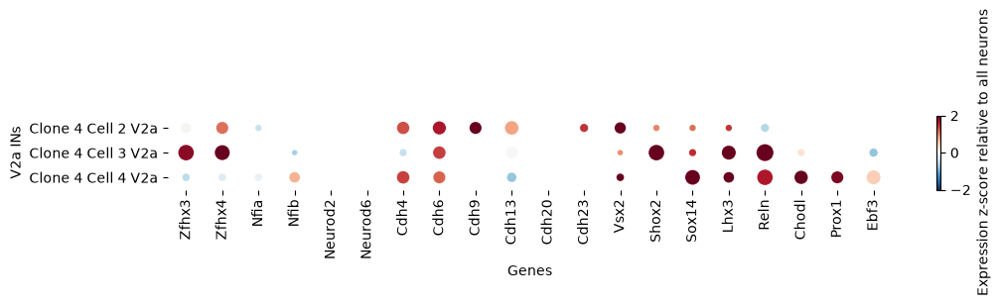

In [156]:
### Dotplot for clonally related V2as

import xenium_config
import cardinal_class_markers

importlib.reload(xenium_config)
importlib.reload(cardinal_class_markers)

### V2a/V2b/V1 clone z-score dotplot (Clones 2, 3, and 4)
### Dot size = MADM log-normalized expression
### Dot color = z-score relative to all reference neurons

MADM_CELLS_TO_PLOT = [
    "435_1",
    "435_2",
    "435_5",
]

V2a_GENES = xenium_config.V2a_GENES.copy()


# Select genes present in BOTH MADM and neuronal reference datasets
genes = [
    g for g in V2a_GENES
    if g in adata_madm_query.var_names
    and g in adata_neurons_SCNeuron_genes.var_names
]

missing_genes = [
    g for g in V2a_GENES
    if g not in adata_madm_query.var_names
    or g not in adata_neurons_SCNeuron_genes.var_names
]

if missing_genes:
    print("Genes not found:", missing_genes)


### Reference mean and SD across all neurons

X_ref = adata_neurons_SCNeuron_genes[:, genes].layers["lognorm"]

if sparse.issparse(X_ref):
    X_ref = X_ref.toarray()

ref_mean = X_ref.mean(axis=0)
ref_std = X_ref.std(axis=0)

# Avoid division by zero
ref_std[ref_std == 0] = 1


### Extract MADM log-normalized expression

X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()


# Create MADM expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


# Calculate MADM z-scores relative to all reference neurons
X_z = (X - ref_mean) / ref_std

madm_zscore_df = pd.DataFrame(
    X_z,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


### Select and order desired cells

missing_cells = [
    cell for cell in MADM_CELLS_TO_PLOT
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]
madm_zscore_df = madm_zscore_df.loc[ordered_cells]


### Convert expression matrix into dotplot format

madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]


# Convert z-score matrix to long format
madm_zscore_long = (
    madm_zscore_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_zscore_long.columns = [
    "Cell_index",
    "Gene",
    "Zscore"
]

madm_dotplot_df["Zscore"] = madm_zscore_long["Zscore"]


# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes


# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()


### Plot

fig, ax = plt.subplots(figsize=(11, 2))

max_expr = madm_dotplot_df["Expression"].max()

scatter = ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    c=madm_dotplot_df["Zscore"],
    cmap="RdBu_r",
    vmin=-2,
    vmax=2,
    edgecolors="none"
)


# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)


# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("V2a INs")


# Z-score colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Expression z-score relative to all neurons")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "V2a_zscore.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

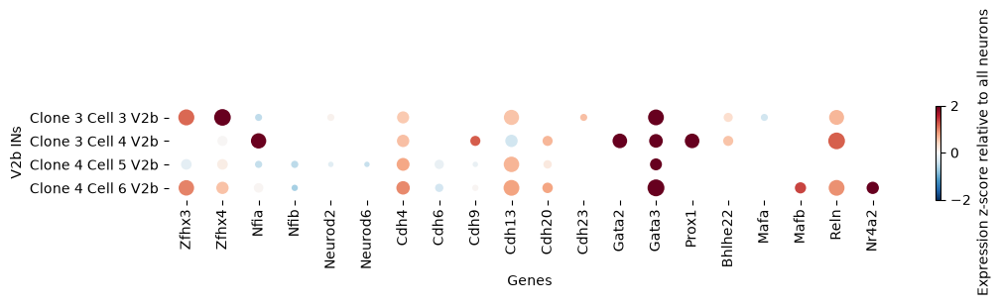

In [157]:
### Dotplot for clonally related V2bs

import xenium_config
import cardinal_class_markers

importlib.reload(xenium_config)
importlib.reload(cardinal_class_markers)

### V2a/V2b/V1 clone z-score dotplot (Clones 2, 3, and 4)
### Dot size = MADM log-normalized expression
### Dot color = z-score relative to all reference neurons

MADM_CELLS_TO_PLOT = [
    "443_0",
    "443_1",
    "435_6",
    "435_0"
]

V2b_GENES = xenium_config.V2b_GENES.copy()


# Select genes present in BOTH MADM and neuronal reference datasets
genes = [
    g for g in V2b_GENES
    if g in adata_madm_query.var_names
    and g in adata_neurons_SCNeuron_genes.var_names
]

missing_genes = [
    g for g in V2b_GENES
    if g not in adata_madm_query.var_names
    or g not in adata_neurons_SCNeuron_genes.var_names
]

if missing_genes:
    print("Genes not found:", missing_genes)


### Reference mean and SD across all neurons

X_ref = adata_neurons_SCNeuron_genes[:, genes].layers["lognorm"]

if sparse.issparse(X_ref):
    X_ref = X_ref.toarray()

ref_mean = X_ref.mean(axis=0)
ref_std = X_ref.std(axis=0)

# Avoid division by zero
ref_std[ref_std == 0] = 1


### Extract MADM log-normalized expression

X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()


# Create MADM expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


# Calculate MADM z-scores relative to all reference neurons
X_z = (X - ref_mean) / ref_std

madm_zscore_df = pd.DataFrame(
    X_z,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


### Select and order desired cells

missing_cells = [
    cell for cell in MADM_CELLS_TO_PLOT
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]
madm_zscore_df = madm_zscore_df.loc[ordered_cells]


### Convert expression matrix into dotplot format

madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]


# Convert z-score matrix to long format
madm_zscore_long = (
    madm_zscore_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_zscore_long.columns = [
    "Cell_index",
    "Gene",
    "Zscore"
]

madm_dotplot_df["Zscore"] = madm_zscore_long["Zscore"]


# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes


# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()


### Plot

fig, ax = plt.subplots(figsize=(11, 2.2))

max_expr = madm_dotplot_df["Expression"].max()

scatter = ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    c=madm_dotplot_df["Zscore"],
    cmap="RdBu_r",
    vmin=-2,
    vmax=2,
    edgecolors="none"
)


# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)


# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("V2b INs")


# Z-score colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Expression z-score relative to all neurons")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "V2b_zscore.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

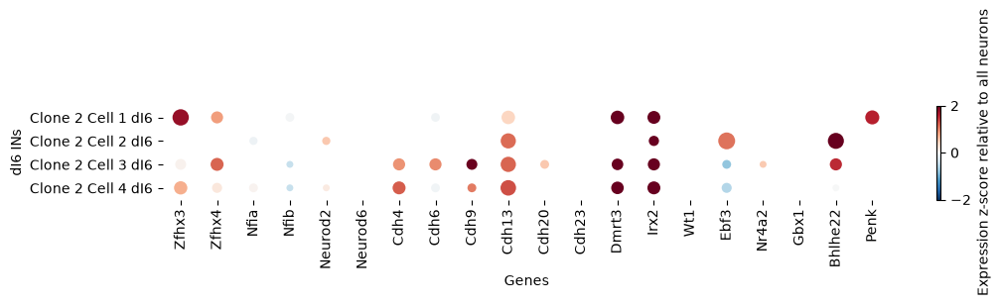

In [158]:
### Dotplot for clonally related dI6s

import xenium_config
import cardinal_class_markers

importlib.reload(xenium_config)
importlib.reload(cardinal_class_markers)

### V2a/V2b/V1 clone z-score dotplot (Clones 2, 3, and 4)
### Dot size = MADM log-normalized expression
### Dot color = z-score relative to all reference neurons

MADM_CELLS_TO_PLOT = [
    '16_0',
    '16_1',
    '16-2_1',
    '16-3_0'
]

dI6_GENES = xenium_config.dI6_GENES.copy()


# Select genes present in BOTH MADM and neuronal reference datasets
genes = [
    g for g in dI6_GENES
    if g in adata_madm_query.var_names
    and g in adata_neurons_SCNeuron_genes.var_names
]

missing_genes = [
    g for g in dI6_GENES
    if g not in adata_madm_query.var_names
    or g not in adata_neurons_SCNeuron_genes.var_names
]

if missing_genes:
    print("Genes not found:", missing_genes)


### Reference mean and SD across all neurons

X_ref = adata_neurons_SCNeuron_genes[:, genes].layers["lognorm"]

if sparse.issparse(X_ref):
    X_ref = X_ref.toarray()

ref_mean = X_ref.mean(axis=0)
ref_std = X_ref.std(axis=0)

# Avoid division by zero
ref_std[ref_std == 0] = 1


### Extract MADM log-normalized expression

X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()


# Create MADM expression DataFrame
madm_expression_df = pd.DataFrame(
    X,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


# Calculate MADM z-scores relative to all reference neurons
X_z = (X - ref_mean) / ref_std

madm_zscore_df = pd.DataFrame(
    X_z,
    index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
    columns=genes
)


### Select and order desired cells

missing_cells = [
    cell for cell in MADM_CELLS_TO_PLOT
    if cell not in madm_expression_df.index
]

if missing_cells:
    print("Cells not found:", missing_cells)

ordered_cells = [
    cell for cell in MADM_ORDER
    if cell in MADM_CELLS_TO_PLOT
    and cell in madm_expression_df.index
]

madm_expression_df = madm_expression_df.loc[ordered_cells]
madm_zscore_df = madm_zscore_df.loc[ordered_cells]


### Convert expression matrix into dotplot format

madm_dotplot_df = (
    madm_expression_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_dotplot_df.columns = [
    "Cell_index",
    "Gene",
    "Expression"
]


# Convert z-score matrix to long format
madm_zscore_long = (
    madm_zscore_df
    .reset_index(drop=True)
    .stack()
    .reset_index()
)

madm_zscore_long.columns = [
    "Cell_index",
    "Gene",
    "Zscore"
]

madm_dotplot_df["Zscore"] = madm_zscore_long["Zscore"]


# Preserve gene order
gene_order = list(madm_expression_df.columns)

madm_dotplot_df["Gene_index"] = pd.Categorical(
    madm_dotplot_df["Gene"],
    categories=gene_order,
    ordered=True
).codes


# Remove zero-expression dots
madm_dotplot_df = madm_dotplot_df[
    madm_dotplot_df["Expression"] > 0
].copy()


### Plot

fig, ax = plt.subplots(figsize=(11, 2.2))

max_expr = madm_dotplot_df["Expression"].max()

scatter = ax.scatter(
    madm_dotplot_df["Gene_index"],
    madm_dotplot_df["Cell_index"],
    s=madm_dotplot_df["Expression"] / max_expr * 150,
    c=madm_dotplot_df["Zscore"],
    cmap="RdBu_r",
    vmin=-2,
    vmax=2,
    edgecolors="none"
)


# Gene labels
ax.set_xticks(np.arange(len(gene_order)))
ax.set_xticklabels(gene_order, rotation=90)


# MADM cell labels
ax.set_yticks(np.arange(len(madm_expression_df)))

ax.set_yticklabels([
    MADM_LABELS_TYPE.get(cell, cell)
    for cell in madm_expression_df.index
])

ax.set_xlim(-0.5, len(gene_order) - 0.5)
ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

ax.set_xlabel("Genes")
ax.set_ylabel("dI6 INs")


# Z-score colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Expression z-score relative to all neurons")

sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    madm_dir / "dI6_zscore.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [49]:
# ### V2a/V2b/V1 clone dotplot (Clone 4)

# MADM_CELLS_TO_PLOT = [
#     "443_0",
#     "443_1",
#     "443_2",
#     "443_3"]
    

# CLONE4_GENES = [
#     'En1',
#     'Foxp2',
#     'Foxp3',
#     'Otp',
#     'Mafa',
#     'Mafb',
#     'Calb1',
#     'Calb2',

#     'Vsx1',
#     'Vsx2',
#     'Sox14',
#     'Shox2',
#     'Lhx3',
#     'Tal1',

#     'Chodl',
#     'Ebf3',

#     'Gata2',
#     'Gata3',
#     'Mnx1',
    
#     'Cdh4',
#     'Cdh6',
#     'Cdh9',
#     'Cdh13',
#     'Cdh20',
#     'Cdh23',
    
# ]
    

# # Select genes that are present in the dataset
# genes = [g for g in CLONE4_GENES if g in adata_madm_query.var_names]

# missing_genes = [g for g in CLONE4_GENES if g not in adata_madm_query.var_names]
# if missing_genes:
#     print("Genes not found:", missing_genes)

# # Extract MADM log-normalized expression
# X = adata_madm_query[:, genes].layers["lognorm"]

# if sparse.issparse(X):
#     X = X.toarray()

# # Create new expression DataFrame
# madm_expression_df = pd.DataFrame(
#     X,
#     index=adata_madm_query.obs["target_cell"].astype(str).to_numpy(),
#     columns=genes
# )

# # Reorder cells using original IDs
# missing_cells = [
#     cell for cell in MADM_ORDER
#     if cell not in madm_expression_df.index
# ]

# if missing_cells:
#     print("Cells not found:", missing_cells)

# # Select only desired cells
# ordered_cells = [
#     cell for cell in MADM_ORDER
#     if cell in MADM_CELLS_TO_PLOT
#     and cell in madm_expression_df.index
# ]

# madm_expression_df = madm_expression_df.loc[ordered_cells]

# # Convert expression matrix into dotplot format
# # Use numeric row positions to handle repeated labels
# madm_dotplot_df = (
#     madm_expression_df
#     .reset_index(drop=True)
#     .stack()
#     .reset_index()
# )

# madm_dotplot_df.columns = [
#     "Cell_index",
#     "Gene",
#     "Expression"
# ]

# # Preserve gene order
# gene_order = list(madm_expression_df.columns)

# madm_dotplot_df["Gene_index"] = pd.Categorical(
#     madm_dotplot_df["Gene"],
#     categories=gene_order,
#     ordered=True
# ).codes

# # Remove zero-expression dots
# madm_dotplot_df = madm_dotplot_df[
#     madm_dotplot_df["Expression"] > 0
# ].copy()

# # Plot
# fig, ax = plt.subplots(figsize=(7,2))

# max_expr = madm_dotplot_df["Expression"].max()

# ax.scatter(
#     madm_dotplot_df["Gene_index"],
#     madm_dotplot_df["Cell_index"],
#     s=madm_dotplot_df["Expression"] / max_expr * 150,
#     color="#A50F15",
#     edgecolors="none"
# )

# # Gene labels
# ax.set_xticks(np.arange(len(gene_order)))
# ax.set_xticklabels(gene_order, rotation=90)

# # MADM cell labels
# ax.set_yticks(np.arange(len(madm_expression_df)))

# ax.set_yticklabels([
#     MADM_LABELS.get(cell, cell)
#     for cell in madm_expression_df.index
# ])

# ax.set_xlim(-0.5, len(gene_order) - 0.5)
# ax.set_ylim(len(madm_expression_df) - 0.5, -0.5)

# ax.set_xlabel("Genes")
# ax.set_ylabel("dI4 clone")

# sns.despine(ax=ax, left=True, bottom=True)

# plt.tight_layout()

# fig.savefig(
#     madm_dir / "Clone4_V2aV2bV1.pdf",
#     dpi=600,
#     bbox_inches="tight"
# )

# plt.show()
# plt.close(fig)

In [50]:
### Save a table with the raw gene expression of MADM cells for the SC-relevant genes

def rename_madm_cell(cell_id):
    for key, new_name in MADM_LABELS.items():
        if key in str(cell_id):
            return new_name
    return cell_id  # keep original if no match
    
unique_values = list(dict.fromkeys(
    value
    for values in custom_SC.values()
    for value in values
))

# Raw counts for MADM cells
madm_raw_select_genes = adata_madm[
    :, unique_values
].to_df(layer="counts")

# Put cell ID into a normal column
madm_raw_select_genes.insert(
    0,
    "cell_id",
    madm_raw_select_genes.index
)

madm_raw_select_genes.insert(
    0,
    "cell_name",
    madm_raw_select_genes["cell_id"].apply(rename_madm_cell)
)

# Save
madm_raw_select_genes.to_csv(
    Path(overall_dir) / "MADM_cells_raw_select_genes.csv",
    index=False
)

madm_raw_select_genes.head()

,cell_name,cell_id,Barhl1,Lhx2,Lhx9,Barhl2,Atoh1,Gad2,Pou4f1,Pax3,...,Gjc3,Gpr17,Opalin,Sema3d,Sox10,Zfp536,Cdh9,Cdh4,Cdh6,Cdh13
obs_name,,,,,,,,,,,,,,,,,,,,,
102760_clone1_16_0_102760 clone 1,Clone 2 Cell 1,102760_clone1_16_0_102760 clone 1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,5.0
102760_clone1_16_1_102760 clone 1,Clone 2 Cell 2,102760_clone1_16_1_102760 clone 1,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,11.0
102760_clone1_16-2_0_102760 clone 1,102760_clone1_16-2_0_102760 clone 1,102760_clone1_16-2_0_102760 clone 1,0.0,0.0,1.0,0.0,0.0,1.0,4.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,4.0
102760_clone1_16-2_1_102760 clone 1,Clone 2 Cell 3,102760_clone1_16-2_1_102760 clone 1,0.0,0.0,0.0,0.0,0.0,12.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,12.0,4.0,6.0,6.0,18.0
102760_clone1_16-3_0_102760 clone 1,Clone 2 Cell 4,102760_clone1_16-3_0_102760 clone 1,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2.0,8.0,2.0,20.0
